# PHASE 9: MACHINE LEARNING AND CUSTOMER CHURN PREDICTION

## 9.1 Introduction and Objectives

This phase focuses on developing machine-learning models to predict customer churn at Meridian Retail Group. The objective is to use historical customer information, purchasing behaviour, and customer-support interactions to identify customers who are likely to stop purchasing from the company.

The analysis will involve defining a suitable churn target variable, selecting relevant predictive features, preparing the modelling dataset, training and evaluating different machine-learning algorithms, and selecting the model that provides the most useful predictions.

The modelling process will also consider the consequences of incorrect predictions. In particular, failing to identify a customer who is likely to churn may result in a lost customer, while incorrectly identifying an active customer as likely to churn may lead to unnecessary retention costs.

### Objectives

The specific objectives of this phase are to:

1. Define the customer churn target variable using an appropriate observation period.
2. Identify and prepare relevant customer, purchasing-behaviour, and customer-support features.
3. Divide the dataset into training and testing subsets using a fixed random seed.
4. Establish a baseline model for comparison.
5. Train and evaluate at least three machine-learning algorithms.
6. Compare model performance using appropriate evaluation metrics.
7. examine possible overfitting and underfitting.
8. Tune the hyperparameters of the most promising models.
9. Apply an ensemble approach where appropriate.
10. Interpret the final model and identify the factors that contribute to churn predictions.
11. Select and justify the most suitable model for predicting customer churn at Meridian Retail Group.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Start research.gsheet', 'MY QUESTIONNAIRE.gform', 'Untitled0.ipynb', 'DATA SCIENCE 1.ipynb', 'Untitled1.ipynb', 'DATA SCIENCE 2', 'Week 2 Ass.ipynb', 'Untitled2.ipynb', 'Canva Presentation - 2026-04-23 16:51:22', 'Canva Presentation - 2026-04-23 16:51:31', 'Canva Presentation - 2026-04-23 16:51:44', 'Canva Presentation - 2026-04-23 16:52:08', 'Canva Presentation - 2026-04-23 16:52:49', 'pora class repetition python.ipynb', 'Colab Notebooks', 'capstone project.gdoc', 'Meridian_Churn_Capstone', 'Untitled document (1).gdoc', 'PHASE 6: DATA CLEANING AND QUALITY ASSESSMENT REPORT.gdoc', 'PHASE 5 REPORT: PYTHON PROGRAMMING REPORT.gdoc', 'onyinyechi PORA Project', 'PHASE 7: EXPLORATORY DATA ANALYSIS AND FEATURE ENGINEERING REPORT.gdoc', 'Untitled document.gdoc', 'PHASE 8: DATA VISUALIZATION AND INTERPRETATION OF FINDINGS.gdoc']


In [ ]:
import os

project_path = '/content/drive/MyDrive/Meridian_Churn_Capstone'

print("Contents of Meridian_Churn_Capstone:")
for item in os.listdir(project_path):
    item_path = os.path.join(project_path, item)

    if os.path.isdir(item_path):
        print("📁 Folder:", item)
    else:
        print("📄 File:", item)

Contents of Meridian_Churn_Capstone:
📄 File: requirements.txt
📁 Folder: Data
📁 Folder: Excel
📁 Folder: Sql
📁 Folder: Notebooks
📁 Folder: Src
📁 Folder: Models
📁 Folder: Api
📁 Folder: Visualizations
📁 Folder: Reports
📁 Folder: Presentation
📁 Folder: README.md
📁 Folder: Outputs


In [ ]:
data_path = os.path.join(project_path, 'Data')

print("Contents of the Data folder:")
for root, folders, files in os.walk(data_path):
    level = root.replace(data_path, '').count(os.sep)
    indent = '  ' * level

    print(f"{indent}📁 {os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  📄 {file}")

Contents of the Data folder:
📁 Data/
  📁 Raw/
    📄 support_tickets.csv
    📄 products.csv
    📄 customers.csv
    📄 orders.csv
    📄 order_items.csv
  📁 Processed/
  📁 Cleaned/
    📄 customers.csv
    📄 products.csv
    📄 orders.csv
    📄 order_items.csv
    📄 support_tickets.csv


In [ ]:
# 9.2 Importing the required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

RANDOM_STATE = 42

print("All required libraries imported successfully.")
print("Random state:", RANDOM_STATE)

All required libraries imported successfully.
Random state: 42


In [ ]:
# 9.3 Loading the cleaned datasets

import os

cleaned_path = os.path.join(
    project_path, 'Data', 'Cleaned'
)

customers = pd.read_csv(os.path.join(cleaned_path, 'customers.csv'))
products = pd.read_csv(os.path.join(cleaned_path, 'products.csv'))
orders = pd.read_csv(os.path.join(cleaned_path, 'orders.csv'))
order_items = pd.read_csv(os.path.join(cleaned_path, 'order_items.csv'))
support_tickets = pd.read_csv(os.path.join(cleaned_path, 'support_tickets.csv'))

# Organise the datasets
datasets = {
    'Customers': customers,
    'Products': products,
    'Orders': orders,
    'Order Items': order_items,
    'Support Tickets': support_tickets
}

# Display the dimensions of each dataset
print("DATASET LOADING SUMMARY")
print("=" * 45)

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows and {df.shape[1]} columns")

print("\nAll five cleaned datasets loaded successfully.")

DATASET LOADING SUMMARY
Customers: 6,090 rows and 22 columns
Products: 220 rows and 11 columns
Orders: 28,272 rows and 12 columns
Order Items: 73,465 rows and 7 columns
Support Tickets: 5,200 rows and 10 columns

All five cleaned datasets loaded successfully.


In [ ]:
# 9.4 Inspecting dataset columns and data types

for name, df in datasets.items():

    print("\n" + "=" * 65)
    print(f"{name.upper()} DATASET")
    print("=" * 65)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)



CUSTOMERS DATASET

Column names:
['customer_id', 'first_name', 'last_name', 'email', 'phone', 'gender', 'date_of_birth', 'signup_date', 'state', 'city', 'membership_tier', 'preferred_channel', 'marketing_opt_in', 'referral_source', 'email_missing', 'phone_missing', 'date_of_birth_missing', 'city_missing', 'marketing_opt_in_missing', 'referral_source_missing', 'dob_before_1900_invalid', 'dob_after_snapshot_invalid']

Data types:
customer_id                   object
first_name                    object
last_name                     object
email                         object
phone                         object
gender                        object
date_of_birth                 object
signup_date                   object
state                         object
city                          object
membership_tier               object
preferred_channel             object
marketing_opt_in              object
referral_source               object
email_missing                  int64
phone_missin

In [ ]:
# 9.5 Inspecting important dates and categorical values

# Convert date columns to datetime
customers['signup_date'] = pd.to_datetime(
    customers['signup_date'], errors='coerce'
)

orders['order_date'] = pd.to_datetime(
    orders['order_date'], errors='coerce'
)

support_tickets['ticket_date'] = pd.to_datetime(
    support_tickets['ticket_date'], errors='coerce'
)

print("1. CUSTOMER SIGNUP DATE RANGE")
print("Earliest:", customers['signup_date'].min())
print("Latest:", customers['signup_date'].max())

print("\n2. ORDER DATE RANGE")
print("Earliest:", orders['order_date'].min())
print("Latest:", orders['order_date'].max())

print("\n3. SUPPORT TICKET DATE RANGE")
print("Earliest:", support_tickets['ticket_date'].min())
print("Latest:", support_tickets['ticket_date'].max())

print("\n4. ORDER STATUS VALUES")
print(orders['order_status'].value_counts(dropna=False))

print("\n5. CUSTOMER ID CHECK")
print("Unique customers:", customers['customer_id'].nunique())
print("Unique order customer IDs:", orders['customer_id'].nunique())
print("Unique support-ticket customer IDs:",
      support_tickets['customer_id'].nunique())

print("\n6. MISSING DATE COUNTS")
print("Missing signup dates:", customers['signup_date'].isna().sum())
print("Missing order dates:", orders['order_date'].isna().sum())
print("Missing ticket dates:", support_tickets['ticket_date'].isna().sum())

1. CUSTOMER SIGNUP DATE RANGE
Earliest: 2020-09-03 00:00:00
Latest: 2026-06-29 00:00:00

2. ORDER DATE RANGE
Earliest: 2020-09-15 00:00:00
Latest: 2026-07-03 00:00:00

3. SUPPORT TICKET DATE RANGE
Earliest: 2024-09-03 00:00:00
Latest: 2026-06-30 00:00:00

4. ORDER STATUS VALUES
order_status
Completed    25481
Returned      1230
Cancelled      976
Pending        585
Name: count, dtype: int64

5. CUSTOMER ID CHECK
Unique customers: 6090
Unique order customer IDs: 5683
Unique support-ticket customer IDs: 3529

6. MISSING DATE COUNTS
Missing signup dates: 0
Missing order dates: 424
Missing ticket dates: 0


In [ ]:
# 9.6 Inspecting customer activity during the outcome period

# Define the outcome period
outcome_start = pd.Timestamp('2026-01-02')
outcome_end = pd.Timestamp('2026-06-30')

# Select valid completed orders within the outcome period
outcome_orders = orders[
    (orders['order_status'].str.strip().str.lower() == 'completed') &
    (orders['order_date'] >= outcome_start) &
    (orders['order_date'] < outcome_end + pd.Timedelta(days=1))
].copy()

# Count completed orders for each customer
outcome_order_counts = (
    outcome_orders.groupby('customer_id')['order_id']
    .nunique()
)

# Add the counts to the complete customer list
customer_activity = customers[['customer_id']].copy()

customer_activity['completed_orders_outcome'] = (
    customer_activity['customer_id']
    .map(outcome_order_counts)
    .fillna(0)
    .astype(int)
)

# Define the churn target
customer_activity['churned'] = (
    customer_activity['completed_orders_outcome'] == 0
).astype(int)

# Summarise the results
print("OUTCOME PERIOD CUSTOMER ACTIVITY")
print("=" * 50)

print("Outcome period:", outcome_start.date(), "to", outcome_end.date())
print("Completed orders:", len(outcome_orders))
print("Customers with completed orders:",
      (customer_activity['churned'] == 0).sum())
print("Customers without completed orders:",
      (customer_activity['churned'] == 1).sum())

print("\nChurn target distribution:")
print(customer_activity['churned'].value_counts())

print("\nChurn percentage:")
print(
    (customer_activity['churned'].value_counts(normalize=True) * 100)
    .round(2)
)

OUTCOME PERIOD CUSTOMER ACTIVITY
Outcome period: 2026-01-02 to 2026-06-30
Completed orders: 4778
Customers with completed orders: 2015
Customers without completed orders: 4075

Churn target distribution:
churned
1    4075
0    2015
Name: count, dtype: int64

Churn percentage:
churned
1    66.91
0    33.09
Name: proportion, dtype: float64


In [ ]:
# 9.7 Creating the customer churn target table

# Keep one record per customer
churn_target = customer_activity[
    ['customer_id', 'churned']
].copy()

# Verify uniqueness and missing values
print("CHURN TARGET VALIDATION")
print("=" * 45)

print("Total customers:", len(churn_target))
print("Unique customer IDs:", churn_target['customer_id'].nunique())
print("Missing churn labels:", churn_target['churned'].isna().sum())

print("\nTarget variable data type:")
print(churn_target['churned'].dtype)

print("\nTarget distribution:")
print(churn_target['churned'].value_counts().sort_index())

print("\nTarget table preview:")
display(churn_target.head(10))

CHURN TARGET VALIDATION
Total customers: 6090
Unique customer IDs: 6090
Missing churn labels: 0

Target variable data type:
int64

Target distribution:
churned
0    2015
1    4075
Name: count, dtype: int64

Target table preview:


,customer_id,churned
0,CUST002565,0
1,CUST004275,1
2,CUST003045,1
3,CUST005168,1
4,CUST003986,1
5,CUST004228,0
6,CUST002495,1
7,CUST004379,1
8,CUST004964,1
9,CUST004930,0


In [ ]:
# 9.8.1 Inspecting historical completed orders

prediction_cutoff = pd.Timestamp('2026-01-02')

historical_orders = orders[
    (orders['order_status'].str.strip().str.lower() == 'completed') &
    (orders['order_date'] < prediction_cutoff) &
    (orders['order_date'].notna())
].copy()

print("HISTORICAL ORDER DATA")
print("=" * 50)

print("Prediction cut-off:", prediction_cutoff.date())
print("Valid historical completed orders:", len(historical_orders))
print("Unique customers with historical completed orders:",
      historical_orders['customer_id'].nunique())

print("\nNumeric order columns:")
print(historical_orders[
    ['shipping_cost', 'discount_pct', 'total_amount']
].describe())

print("\nHistorical order preview:")
display(historical_orders.head())

HISTORICAL ORDER DATA
Prediction cut-off: 2026-01-02
Valid historical completed orders: 20313
Unique customers with historical completed orders: 5131

Numeric order columns:
       shipping_cost  discount_pct  total_amount
count   20305.000000  20313.000000  20313.000000
mean        5.297118      3.479299   1533.092981
std         4.517037      6.392095   1167.680947
min         0.000000      0.000000      7.070000
25%         0.000000      0.000000    668.460000
50%         4.990000      0.000000   1253.100000
75%         7.990000      5.000000   2110.790000
max        12.990000     25.000000   9937.540000

Historical order preview:


,order_id,customer_id,order_date,channel,order_status,payment_method,shipping_cost,discount_pct,total_amount,order_date_missing,negative_shipping_cost_invalid,customer_reference_missing
1,ORD103955,CUST004689,2021-06-07,Mobile App,Completed,Paypal,0.00,0,349.47,0,False,0
2,ORD102242,CUST006035,2023-06-01,Online,Completed,Debit Card,12.99,15,981.00,0,False,0
4,ORD108154,CUST000471,2022-06-28,Mobile App,Completed,Debit Card,5.99,0,225.89,0,False,0
5,ORD113987,CUST000425,2022-09-12,Mobile App,Completed,Gift Card,7.99,0,1290.54,0,False,0
6,ORD109948,CUST004346,2023-06-04,Online,Completed,Gift Card,0.00,0,486.62,0,False,0


In [ ]:
# 9.8.2 Creating historical purchasing features

# Prepare order-item data
historical_order_ids = historical_orders['order_id']

historical_items = order_items[
    order_items['order_id'].isin(historical_order_ids)
].copy()

# Aggregate purchasing behaviour at customer level
historical_order_features = (
    historical_orders.groupby('customer_id')
    .agg(
        historical_frequency=('order_id', 'nunique'),
        historical_monetary=('total_amount', 'sum'),
        last_purchase_date=('order_date', 'max'),
        historical_avg_order_value=('total_amount', 'mean')
    )
    .reset_index()
)

# Calculate historical recency
historical_order_features['historical_recency'] = (
    prediction_cutoff -
    historical_order_features['last_purchase_date']
).dt.days

# Aggregate total quantity purchased
historical_quantity = (
    historical_items.groupby('order_id')['quantity']
    .sum()
    .rename('order_quantity')
)

historical_orders_with_quantity = historical_orders[
    ['order_id', 'customer_id']
].merge(
    historical_quantity,
    on='order_id',
    how='left'
)

customer_quantity = (
    historical_orders_with_quantity.groupby('customer_id')
    ['order_quantity']
    .sum()
    .rename('historical_quantity')
    .reset_index()
)

# Combine purchasing features
historical_order_features = historical_order_features.merge(
    customer_quantity,
    on='customer_id',
    how='left'
)

# Retain all 6,090 customers
historical_order_features = customers[
    ['customer_id']
].merge(
    historical_order_features,
    on='customer_id',
    how='left'
)

# Customers without historical purchases
zero_features = [
    'historical_frequency',
    'historical_monetary',
    'historical_quantity'
]

historical_order_features[zero_features] = (
    historical_order_features[zero_features].fillna(0)
)

print("HISTORICAL PURCHASING FEATURES")
print("=" * 55)

print("Total customer records:",
      len(historical_order_features))

print("Customers with no historical completed orders:",
      historical_order_features['historical_frequency'].eq(0).sum())

print("\nFeature summary:")
display(
    historical_order_features[
        [
            'historical_frequency',
            'historical_monetary',
            'historical_recency',
            'historical_avg_order_value',
            'historical_quantity'
        ]
    ].describe().round(2)
)

print("\nSample records:")
display(historical_order_features.head(10))

HISTORICAL PURCHASING FEATURES
Total customer records: 6090
Customers with no historical completed orders: 973

Feature summary:


,historical_frequency,historical_monetary,historical_recency,historical_avg_order_value,historical_quantity
count,6090.00,6090.00,5117.00,5117.00,6090.00
mean,3.33,5109.96,288.41,1533.15,13.42
std,2.25,4062.84,268.18,673.48,10.08
min,0.00,0.00,1.00,12.84,0.00
25%,2.00,1895.12,78.00,1082.48,6.00
50%,3.00,4660.29,215.00,1455.34,13.00
75%,5.00,7691.54,426.00,1891.89,20.00
max,14.00,35395.37,1935.00,8171.61,70.00



Sample records:


,customer_id,historical_frequency,historical_monetary,last_purchase_date,historical_avg_order_value,historical_recency,historical_quantity
0,CUST002565,0.0,0.00,NaT,NaN,NaN,0.0
1,CUST004275,0.0,0.00,NaT,NaN,NaN,0.0
2,CUST003045,3.0,8742.62,2024-09-05,2914.206667,484.0,13.0
3,CUST005168,4.0,9395.18,2025-12-27,2348.795000,6.0,23.0
4,CUST003986,4.0,4670.25,2024-09-21,1167.562500,468.0,11.0
5,CUST004228,4.0,9654.08,2025-11-27,2413.520000,36.0,31.0
6,CUST002495,3.0,3676.19,2024-03-15,1225.396667,658.0,7.0
7,CUST004379,3.0,3673.21,2025-04-03,1224.403333,274.0,10.0
8,CUST004964,3.0,5057.26,2025-09-13,1685.753333,111.0,9.0
9,CUST004930,2.0,4262.38,2025-10-24,2131.190000,70.0,10.0


In [ ]:
# 9.8.3 Investigating the historical customer-count discrepancy

# Count customers directly from the historical order records
direct_customer_count = historical_orders['customer_id'].nunique()

# Count customers with positive frequency in the engineered features
feature_customer_count = (
    historical_order_features['historical_frequency'] > 0
).sum()

# Identify customers in the customer table but absent from historical orders
customers_without_orders = set(customers['customer_id']) - set(
    historical_orders['customer_id']
)

# Identify customers whose feature frequency is zero
customers_zero_frequency = set(
    historical_order_features.loc[
        historical_order_features['historical_frequency'] == 0,
        'customer_id'
    ]
)

# Compare the two groups
print("HISTORICAL CUSTOMER-COUNT INVESTIGATION")
print("=" * 55)

print("Unique customers in historical orders:",
      direct_customer_count)

print("Customers with positive engineered frequency:",
      feature_customer_count)

print("Customers absent from historical orders:",
      len(customers_without_orders))

print("Customers with zero engineered frequency:",
      len(customers_zero_frequency))

print("\nDifference between the two customer groups:",
      len(customers_zero_frequency - customers_without_orders))

print("\nAre the two groups identical?",
      customers_zero_frequency == customers_without_orders)

HISTORICAL CUSTOMER-COUNT INVESTIGATION
Unique customers in historical orders: 5131
Customers with positive engineered frequency: 5117
Customers absent from historical orders: 973
Customers with zero engineered frequency: 973

Difference between the two customer groups: 0

Are the two groups identical? True


In [ ]:
# 9.8.4 Inspecting customer profile features

# Calculate customer tenure as at the prediction cut-off
customer_profile = customers.copy()

customer_profile['signup_date'] = pd.to_datetime(
    customer_profile['signup_date'],
    errors='coerce'
)

customer_profile['customer_tenure_days'] = (
    prediction_cutoff - customer_profile['signup_date']
).dt.days

print("CUSTOMER PROFILE INSPECTION")
print("=" * 55)

print("\nMembership tier distribution:")
print(customer_profile['membership_tier'].value_counts(dropna=False))

print("\nPreferred channel distribution:")
print(customer_profile['preferred_channel'].value_counts(dropna=False))

print("\nGender distribution:")
print(customer_profile['gender'].value_counts(dropna=False))

print("\nMarketing opt-in distribution:")
print(customer_profile['marketing_opt_in'].value_counts(dropna=False))

print("\nReferral source distribution:")
print(customer_profile['referral_source'].value_counts(dropna=False))

print("\nCustomer tenure summary:")
print(customer_profile['customer_tenure_days'].describe().round(2))

print("\nMissing values in proposed profile features:")
print(
    customer_profile[
        [
            'membership_tier',
            'preferred_channel',
            'gender',
            'state',
            'marketing_opt_in',
            'referral_source',
            'customer_tenure_days'
        ]
    ].isna().sum()
)

CUSTOMER PROFILE INSPECTION

Membership tier distribution:
membership_tier
Bronze      2785
Silver      1768
Gold        1126
Platinum     411
Name: count, dtype: int64

Preferred channel distribution:
preferred_channel
Mobile App    2053
In-Store      2041
Online        1996
Name: count, dtype: int64

Gender distribution:
gender
M        2530
F        2363
Other    1197
Name: count, dtype: int64

Marketing opt-in distribution:
marketing_opt_in
Yes    2453
No     2446
NaN    1191
Name: count, dtype: int64

Referral source distribution:
referral_source
NaN                1705
Social Media        650
Walk-In             649
Tv Ad               635
Influencer          629
Friend Referral     614
Email Campaign      604
Search Engine       604
Name: count, dtype: int64

Customer tenure summary:
count    6090.00
mean      872.75
std       612.53
min      -178.00
25%       333.50
50%       871.00
75%      1405.00
max      1947.00
Name: customer_tenure_days, dtype: float64

Missing values in 

In [ ]:
# 9.8.5 Investigating customers who registered after the prediction cut-off

# Identify customers whose signup dates are after the cut-off
future_signup_customers = customer_profile[
    customer_profile['signup_date'] >= prediction_cutoff
].copy()

print("CUSTOMERS REGISTERED ON OR AFTER THE PREDICTION CUT-OFF")
print("=" * 65)

print("Number of affected customers:",
      len(future_signup_customers))

print("\nSignup date distribution:")
print(
    future_signup_customers['signup_date']
    .value_counts()
    .sort_index()
)

print("\nAffected customer sample:")
display(
    future_signup_customers[
        [
            'customer_id',
            'signup_date',
            'membership_tier',
            'preferred_channel'
        ]
    ].head(15)
)

print("\nCheck target classification of affected customers:")

future_signup_target = future_signup_customers[
    ['customer_id']
].merge(
    churn_target,
    on='customer_id',
    how='left'
)

print(future_signup_target['churned'].value_counts(dropna=False))

CUSTOMERS REGISTERED ON OR AFTER THE PREDICTION CUT-OFF
Number of affected customers: 526

Signup date distribution:
signup_date
2026-01-02    5
2026-01-04    2
2026-01-05    3
2026-01-06    3
2026-01-07    3
             ..
2026-06-25    2
2026-06-26    2
2026-06-27    1
2026-06-28    1
2026-06-29    2
Name: count, Length: 171, dtype: int64

Affected customer sample:


,customer_id,signup_date,membership_tier,preferred_channel
0,CUST002565,2026-05-28,Silver,Online
22,CUST003144,2026-04-29,Silver,Online
52,CUST001172,2026-02-12,Silver,Online
54,CUST005185,2026-02-23,Silver,Online
55,CUST005675,2026-04-22,Silver,In-Store
63,CUST000594,2026-05-09,Gold,Online
78,CUST003465,2026-04-30,Platinum,Online
96,CUST004341,2026-04-30,Bronze,In-Store
157,CUST003832,2026-03-20,Silver,In-Store
171,CUST000259,2026-03-01,Silver,Online



Check target classification of affected customers:
churned
0    447
1     79
Name: count, dtype: int64


In [ ]:
# 9.8.6 Creating the eligible modelling population

# Include only customers who registered before the prediction cut-off
eligible_customers = customer_profile[
    customer_profile['signup_date'] < prediction_cutoff
][['customer_id']].copy()

# Attach the verified churn target
eligible_target = eligible_customers.merge(
    churn_target,
    on='customer_id',
    how='left'
)

print("ELIGIBLE MODELLING POPULATION")
print("=" * 55)

print("Original customer population:", len(customers))
print("Eligible customers:", len(eligible_customers))
print("Excluded post-cut-off customers:",
      len(customers) - len(eligible_customers))

print("\nEligible customer churn distribution:")
print(eligible_target['churned'].value_counts().sort_index())

print("\nEligible customer churn percentages:")
print(
    (eligible_target['churned'].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nMissing target labels:",
      eligible_target['churned'].isna().sum())

ELIGIBLE MODELLING POPULATION
Original customer population: 6090
Eligible customers: 5564
Excluded post-cut-off customers: 526

Eligible customer churn distribution:
churned
0    1568
1    3996
Name: count, dtype: int64

Eligible customer churn percentages:
churned
1    71.82
0    28.18
Name: proportion, dtype: float64

Missing target labels: 0


In [ ]:
# 9.8.7 Restricting historical features to eligible customers

eligible_historical_features = historical_order_features[
    historical_order_features['customer_id'].isin(
        eligible_customers['customer_id']
    )
].copy()

print("ELIGIBLE HISTORICAL FEATURE CHECK")
print("=" * 55)

print("Eligible customers:", len(eligible_customers))
print("Eligible historical feature records:",
      len(eligible_historical_features))

print("\nDuplicate customer IDs:",
      eligible_historical_features['customer_id'].duplicated().sum())

print("\nCustomers with no historical completed orders:",
      (eligible_historical_features['historical_frequency'] == 0).sum())

print("\nMissing values in historical features:")
print(eligible_historical_features.isna().sum())

ELIGIBLE HISTORICAL FEATURE CHECK
Eligible customers: 5564
Eligible historical feature records: 5564

Duplicate customer IDs: 0

Customers with no historical completed orders: 490

Missing values in historical features:
customer_id                     0
historical_frequency            0
historical_monetary             0
last_purchase_date            490
historical_avg_order_value    490
historical_recency            490
historical_quantity             0
dtype: int64


In [ ]:
# 9.8.8 Preparing eligible customer profile features

eligible_profile_features = customer_profile[
    customer_profile['customer_id'].isin(
        eligible_customers['customer_id']
    )
].copy()

# Select relevant customer profile variables
eligible_profile_features = eligible_profile_features[
    [
        'customer_id',
        'membership_tier',
        'preferred_channel',
        'state',
        'marketing_opt_in',
        'referral_source',
        'customer_tenure_days'
    ]
].copy()

# Represent missing categorical values explicitly
eligible_profile_features['marketing_opt_in'] = (
    eligible_profile_features['marketing_opt_in']
    .fillna('Unknown')
)

eligible_profile_features['referral_source'] = (
    eligible_profile_features['referral_source']
    .fillna('Unknown / Not Recorded')
)

print("ELIGIBLE CUSTOMER PROFILE CHECK")
print("=" * 55)

print("Eligible customers:", len(eligible_customers))
print("Profile feature records:", len(eligible_profile_features))

print("\nDuplicate customer IDs:",
      eligible_profile_features['customer_id'].duplicated().sum())

print("\nMissing values:")
print(eligible_profile_features.isna().sum())

print("\nMembership tier distribution:")
print(eligible_profile_features['membership_tier'].value_counts())

print("\nPreferred channel distribution:")
print(eligible_profile_features['preferred_channel'].value_counts())

print("\nMarketing opt-in distribution:")
print(eligible_profile_features['marketing_opt_in'].value_counts())

print("\nReferral source distribution:")
print(eligible_profile_features['referral_source'].value_counts())

print("\nCustomer tenure summary:")
print(eligible_profile_features['customer_tenure_days'].describe())

ELIGIBLE CUSTOMER PROFILE CHECK
Eligible customers: 5564
Profile feature records: 5564

Duplicate customer IDs: 0

Missing values:
customer_id             0
membership_tier         0
preferred_channel       0
state                   0
marketing_opt_in        0
referral_source         0
customer_tenure_days    0
dtype: int64

Membership tier distribution:
membership_tier
Bronze      2546
Silver      1621
Gold        1027
Platinum     370
Name: count, dtype: int64

Preferred channel distribution:
preferred_channel
Mobile App    1886
In-Store      1860
Online        1818
Name: count, dtype: int64

Marketing opt-in distribution:
marketing_opt_in
Yes        2239
No         2229
Unknown    1096
Name: count, dtype: int64

Referral source distribution:
referral_source
Unknown / Not Recorded    1577
Social Media               598
Walk-In                    588
Tv Ad                      581
Friend Referral            571
Influencer                 563
Search Engine              546
Email Campai

Check	Result	Interpretation
Eligible customers	5,564	Correct population
Profile records	5,564	All eligible customers represented
Duplicate customer IDs	0	No duplicate customer records
Missing feature values	0	All selected profile features are complete

B. Customer profile characteristics
- Membership tier: Bronze has the highest representation (2,546), while Platinum has the lowest (370).
- Preferred channel: Mobile App, In-Store and Online are relatively evenly represented.
- Marketing opt-in: 2,239 customers opted in, 2,229 opted out, and 1,096 have unknown consent information. Keeping Unknown separate is important because missing consent information does not mean that a customer opted out.
- Referral source: 1,577 customers have no recorded referral source. We have retained this as a distinct category rather than assigning an assumed source.

C. Customer tenure
Validation passed
- Minimum tenure: 1 day.
- Average tenure: approximately 964 days.
- Median tenure: approximately 957 days.
- Maximum tenure: 1,947 days.
The minimum tenure is now positive, confirming that the earlier post-cut-off signup issue has been resolved by restricting the population to customers registered before the prediction cut-off.

In [ ]:
# 9.8.9 Inspecting support-ticket data before feature engineering

print("SUPPORT TICKET DATA INSPECTION")
print("=" * 55)

print("Total support tickets:", len(support_tickets))

print("\nTicket date range:")
print("Earliest ticket:", support_tickets['ticket_date'].min())
print("Latest ticket:", support_tickets['ticket_date'].max())

print("\nMissing values:")
print(support_tickets.isna().sum())

print("\nIssue category distribution:")
print(support_tickets['issue_category'].value_counts(dropna=False))

print("\nSupport channel distribution:")
print(support_tickets['channel'].value_counts(dropna=False))

print("\nUnique customers with support tickets:",
      support_tickets['customer_id'].nunique())

print("\nUnique customers with support tickets "
      "in the eligible population:",
      support_tickets[
          support_tickets['customer_id'].isin(
              eligible_customers['customer_id']
          )
      ]['customer_id'].nunique())

SUPPORT TICKET DATA INSPECTION
Total support tickets: 5200

Ticket date range:
Earliest ticket: 2024-09-03 00:00:00
Latest ticket: 2026-06-30 00:00:00

Missing values:
ticket_id                             0
customer_id                           0
ticket_date                           0
issue_category                        0
channel                               0
resolution_time_hours                 6
satisfaction_score                  592
ticket_text                           0
satisfaction_score_missing            0
negative_resolution_time_invalid      0
dtype: int64

Issue category distribution:
issue_category
Product Question      715
Refund Status         671
Damaged Item          663
Account Access        661
Return Request        641
Billing Issue         633
Delivery Delay        615
Wrong Item Shipped    601
Name: count, dtype: int64

Support channel distribution:
channel
Phone           1343
Social Media    1304
Live Chat       1301
Email           1252
Name: count, dtyp

In [ ]:
# 9.8.10 Filtering support tickets before the prediction cut-off

historical_support_tickets = support_tickets[
    (support_tickets['ticket_date'] < prediction_cutoff) &
    (support_tickets['customer_id'].isin(
        eligible_customers['customer_id']
    ))
].copy()

print("HISTORICAL SUPPORT TICKET CHECK")
print("=" * 55)

print("Total support tickets:", len(support_tickets))

print("Eligible historical support tickets:",
      len(historical_support_tickets))

print("\nHistorical ticket date range:")
print("Earliest:",
      historical_support_tickets['ticket_date'].min())

print("Latest:",
      historical_support_tickets['ticket_date'].max())

print("\nUnique eligible customers with historical tickets:",
      historical_support_tickets['customer_id'].nunique())

print("\nTickets dated on or after prediction cut-off:",
      (historical_support_tickets['ticket_date'] >= prediction_cutoff).sum())

print("\nMissing resolution times:",
      historical_support_tickets['resolution_time_hours'].isna().sum())

print("\nMissing satisfaction scores:",
      historical_support_tickets['satisfaction_score'].isna().sum())

HISTORICAL SUPPORT TICKET CHECK
Total support tickets: 5200
Eligible historical support tickets: 3468

Historical ticket date range:
Earliest: 2024-09-03 00:00:00
Latest: 2026-01-01 00:00:00

Unique eligible customers with historical tickets: 2613

Tickets dated on or after prediction cut-off: 0

Missing resolution times: 3

Missing satisfaction scores: 393


In [ ]:
# 9.8.11 Aggregating historical support tickets by customer

historical_support_features = (
    historical_support_tickets
    .groupby('customer_id')
    .agg(
        historical_ticket_count=('ticket_id', 'nunique'),

        historical_avg_resolution_hours=(
            'resolution_time_hours', 'mean'
        ),

        historical_avg_satisfaction=(
            'satisfaction_score', 'mean'
        ),

        historical_unique_issue_categories=(
            'issue_category', 'nunique'
        ),

        historical_missing_satisfaction_count=(
            'satisfaction_score_missing', 'sum'
        )
    )
    .reset_index()
)

print("HISTORICAL SUPPORT FEATURE SUMMARY")
print("=" * 60)

print("Customers with support feature records:",
      len(historical_support_features))

print("\nDuplicate customer IDs:",
      historical_support_features['customer_id'].duplicated().sum())

print("\nFeature summary:")
print(
    historical_support_features.drop(
        columns=['customer_id']
    ).describe().round(2)
)

print("\nMissing values in aggregated features:")
print(historical_support_features.isna().sum())

HISTORICAL SUPPORT FEATURE SUMMARY
Customers with support feature records: 2613

Duplicate customer IDs: 0

Feature summary:
       historical_ticket_count  historical_avg_resolution_hours  \
count                  2613.00                          2611.00   
mean                      1.33                            18.13   
std                       0.61                            19.07   
min                       1.00                             0.00   
25%                       1.00                             6.20   
50%                       1.00                            13.25   
75%                       2.00                            24.20   
max                       5.00                           374.00   

       historical_avg_satisfaction  historical_unique_issue_categories  \
count                      2383.00                             2613.00   
mean                          3.90                                1.28   
std                           1.09               

In [ ]:
# 9.8.12 Expanding support features to all eligible customers

eligible_support_features = eligible_customers.merge(
    historical_support_features,
    on='customer_id',
    how='left'
)

# Customers without historical tickets receive zero ticket counts
count_columns = [
    'historical_ticket_count',
    'historical_unique_issue_categories',
    'historical_missing_satisfaction_count'
]

eligible_support_features[count_columns] = (
    eligible_support_features[count_columns].fillna(0)
)

print("ELIGIBLE SUPPORT FEATURE VALIDATION")
print("=" * 60)

print("Eligible customers:",
      len(eligible_customers))

print("Support feature records:",
      len(eligible_support_features))

print("\nDuplicate customer IDs:",
      eligible_support_features['customer_id'].duplicated().sum())

print("\nCustomers with no historical tickets:",
      (eligible_support_features['historical_ticket_count'] == 0).sum())

print("\nCustomers with historical tickets:",
      (eligible_support_features['historical_ticket_count'] > 0).sum())

print("\nMissing values:")
print(eligible_support_features.isna().sum())

print("\nSupport feature summary:")
print(
    eligible_support_features.drop(
        columns=['customer_id']
    ).describe().round(2)
)

ELIGIBLE SUPPORT FEATURE VALIDATION
Eligible customers: 5564
Support feature records: 5564

Duplicate customer IDs: 0

Customers with no historical tickets: 2951

Customers with historical tickets: 2613

Missing values:
customer_id                                 0
historical_ticket_count                     0
historical_avg_resolution_hours          2953
historical_avg_satisfaction              3181
historical_unique_issue_categories          0
historical_missing_satisfaction_count       0
dtype: int64

Support feature summary:
       historical_ticket_count  historical_avg_resolution_hours  \
count                  5564.00                          2611.00   
mean                      0.62                            18.13   
std                       0.78                            19.07   
min                       0.00                             0.00   
25%                       0.00                             6.20   
50%                       0.00                            13.25

In [ ]:
# 9.8.13 Combining the three customer feature groups

# Merge historical purchasing features with customer profiles
modelling_features = eligible_historical_features.merge(
    eligible_profile_features,
    on='customer_id',
    how='inner'
)

# Add historical support features
modelling_features = modelling_features.merge(
    eligible_support_features,
    on='customer_id',
    how='inner'
)

print("COMBINED MODELLING FEATURES CHECK")
print("=" * 60)

print("Eligible customers:", len(eligible_customers))
print("Combined feature records:", len(modelling_features))
print("Number of columns:", len(modelling_features.columns))

print("\nDuplicate customer IDs:",
      modelling_features['customer_id'].duplicated().sum())

print("\nColumn names:")
print(modelling_features.columns.tolist())

print("\nMissing values by column:")
print(modelling_features.isna().sum())

print("\nFirst five records:")
display(modelling_features.head())

COMBINED MODELLING FEATURES CHECK
Eligible customers: 5564
Combined feature records: 5564
Number of columns: 18

Duplicate customer IDs: 0

Column names:
['customer_id', 'historical_frequency', 'historical_monetary', 'last_purchase_date', 'historical_avg_order_value', 'historical_recency', 'historical_quantity', 'membership_tier', 'preferred_channel', 'state', 'marketing_opt_in', 'referral_source', 'customer_tenure_days', 'historical_ticket_count', 'historical_avg_resolution_hours', 'historical_avg_satisfaction', 'historical_unique_issue_categories', 'historical_missing_satisfaction_count']

Missing values by column:
customer_id                                 0
historical_frequency                        0
historical_monetary                         0
last_purchase_date                        490
historical_avg_order_value                490
historical_recency                        490
historical_quantity                         0
membership_tier                             0
preferr

,customer_id,historical_frequency,historical_monetary,last_purchase_date,historical_avg_order_value,historical_recency,historical_quantity,membership_tier,preferred_channel,state,marketing_opt_in,referral_source,customer_tenure_days,historical_ticket_count,historical_avg_resolution_hours,historical_avg_satisfaction,historical_unique_issue_categories,historical_missing_satisfaction_count
0,CUST004275,0.0,0.00,NaT,NaN,NaN,0.0,Silver,In-Store,Massachusetts,No,Search Engine,1106,0.0,NaN,NaN,0.0,0.0
1,CUST003045,3.0,8742.62,2024-09-05,2914.206667,484.0,13.0,Bronze,In-Store,Wisconsin,Yes,Tv Ad,1272,1.0,20.0,5.0,1.0,0.0
2,CUST005168,4.0,9395.18,2025-12-27,2348.795000,6.0,23.0,Bronze,Online,In,Yes,Friend Referral,1156,0.0,NaN,NaN,0.0,0.0
3,CUST003986,4.0,4670.25,2024-09-21,1167.562500,468.0,11.0,Silver,Online,Tx,Yes,Unknown / Not Recorded,912,1.0,34.7,4.0,1.0,0.0
4,CUST004228,4.0,9654.08,2025-11-27,2413.520000,36.0,31.0,Bronze,In-Store,Nc,Unknown,Unknown / Not Recorded,1240,0.0,NaN,NaN,0.0,0.0


In [ ]:
# 9.8.14 Investigating state category consistency

print("STATE CATEGORY INVESTIGATION")
print("=" * 55)

print("Number of unique state values:",
      modelling_features['state'].nunique())

print("\nAll unique state values:")
print(
    sorted(
        modelling_features['state'].dropna().unique()
    )
)

print("\nState frequency distribution:")
print(
    modelling_features['state'].value_counts(dropna=False)
)

STATE CATEGORY INVESTIGATION
Number of unique state values: 40

All unique state values:
['Arizona', 'Az', 'Ca', 'California', 'Fl', 'Florida', 'Ga', 'Georgia', 'Il', 'Illinois', 'In', 'Indiana', 'Ma', 'Maryland', 'Massachusetts', 'Md', 'Mi', 'Michigan', 'Missouri', 'Mo', 'Nc', 'New Jersey', 'New York', 'Nj', 'North Carolina', 'Ny', 'Oh', 'Ohio', 'Pa', 'Pennsylvania', 'Tennessee', 'Texas', 'Tn', 'Tx', 'Va', 'Virginia', 'Wa', 'Washington', 'Wi', 'Wisconsin']

State frequency distribution:
state
Wisconsin         159
Missouri          157
Illinois          154
Oh                153
Va                151
California        151
Tennessee         149
Tx                149
Ga                149
Az                149
Arizona           149
Ny                148
Washington        146
Georgia           146
Pennsylvania      145
Maryland          143
Mo                142
New York          142
New Jersey        141
Ca                140
Mi                138
Nj                138
Fl               

In [ ]:
# 9.8.15 Standardising state names

state_mapping = {
    'Az': 'Arizona',
    'Ca': 'California',
    'Fl': 'Florida',
    'Ga': 'Georgia',
    'Il': 'Illinois',
    'In': 'Indiana',
    'Ma': 'Massachusetts',
    'Md': 'Maryland',
    'Mi': 'Michigan',
    'Mo': 'Missouri',
    'Nc': 'North Carolina',
    'Nj': 'New Jersey',
    'Ny': 'New York',
    'Oh': 'Ohio',
    'Pa': 'Pennsylvania',
    'Tn': 'Tennessee',
    'Tx': 'Texas',
    'Va': 'Virginia',
    'Wa': 'Washington',
    'Wi': 'Wisconsin'
}

# Apply standardisation
modelling_features['state'] = (
    modelling_features['state']
    .replace(state_mapping)
)

print("STATE STANDARDISATION CHECK")
print("=" * 55)

print("Unique state values after standardisation:",
      modelling_features['state'].nunique())

print("\nStandardised state categories:")
print(
    sorted(modelling_features['state'].dropna().unique())
)

print("\nState frequency distribution:")
print(
    modelling_features['state'].value_counts().sort_index()
)

STATE STANDARDISATION CHECK
Unique state values after standardisation: 20

Standardised state categories:
['Arizona', 'California', 'Florida', 'Georgia', 'Illinois', 'Indiana', 'Maryland', 'Massachusetts', 'Michigan', 'Missouri', 'New Jersey', 'New York', 'North Carolina', 'Ohio', 'Pennsylvania', 'Tennessee', 'Texas', 'Virginia', 'Washington', 'Wisconsin']

State frequency distribution:
state
Arizona           298
California        291
Florida           273
Georgia           295
Illinois          286
Indiana           265
Maryland          270
Massachusetts     265
Michigan          270
Missouri          299
New Jersey        279
New York          290
North Carolina    239
Ohio              262
Pennsylvania      280
Tennessee         282
Texas             276
Virginia          282
Washington        275
Wisconsin         287
Name: count, dtype: int64


In [ ]:
# 9.8.16 Creating the complete modelling dataset

modelling_data = modelling_features.merge(
    eligible_target[['customer_id', 'churned']],
    on='customer_id',
    how='left'
)

print("FINAL MODELLING DATASET CHECK")
print("=" * 60)

print("Number of records:", len(modelling_data))
print("Number of columns:", len(modelling_data.columns))

print("\nDuplicate customer IDs:",
      modelling_data['customer_id'].duplicated().sum())

print("\nMissing churn labels:",
      modelling_data['churned'].isna().sum())

print("\nChurn target distribution:")
print(modelling_data['churned'].value_counts().sort_index())

print("\nChurn target percentages:")
print(
    (modelling_data['churned'].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nDataset preview:")
display(modelling_data.head())

FINAL MODELLING DATASET CHECK
Number of records: 5564
Number of columns: 19

Duplicate customer IDs: 0

Missing churn labels: 0

Churn target distribution:
churned
0    1568
1    3996
Name: count, dtype: int64

Churn target percentages:
churned
1    71.82
0    28.18
Name: proportion, dtype: float64

Dataset preview:


,customer_id,historical_frequency,historical_monetary,last_purchase_date,historical_avg_order_value,historical_recency,historical_quantity,membership_tier,preferred_channel,state,marketing_opt_in,referral_source,customer_tenure_days,historical_ticket_count,historical_avg_resolution_hours,historical_avg_satisfaction,historical_unique_issue_categories,historical_missing_satisfaction_count,churned
0,CUST004275,0.0,0.00,NaT,NaN,NaN,0.0,Silver,In-Store,Massachusetts,No,Search Engine,1106,0.0,NaN,NaN,0.0,0.0,1
1,CUST003045,3.0,8742.62,2024-09-05,2914.206667,484.0,13.0,Bronze,In-Store,Wisconsin,Yes,Tv Ad,1272,1.0,20.0,5.0,1.0,0.0,1
2,CUST005168,4.0,9395.18,2025-12-27,2348.795000,6.0,23.0,Bronze,Online,Indiana,Yes,Friend Referral,1156,0.0,NaN,NaN,0.0,0.0,1
3,CUST003986,4.0,4670.25,2024-09-21,1167.562500,468.0,11.0,Silver,Online,Texas,Yes,Unknown / Not Recorded,912,1.0,34.7,4.0,1.0,0.0,1
4,CUST004228,4.0,9654.08,2025-11-27,2413.520000,36.0,31.0,Bronze,In-Store,North Carolina,Unknown,Unknown / Not Recorded,1240,0.0,NaN,NaN,0.0,0.0,0


In [ ]:
# 9.8.17 Separating predictors and target variable

# Remove identification and raw date columns
columns_to_exclude = [
    'customer_id',
    'last_purchase_date',
    'churned'
]

# Create predictor dataset
X = modelling_data.drop(columns=columns_to_exclude)

# Create target variable
y = modelling_data['churned']

print("PREDICTOR AND TARGET SEPARATION")
print("=" * 60)

print("Predictor records:", X.shape[0])
print("Number of predictors:", X.shape[1])

print("\nTarget records:", y.shape[0])

print("\nPredictor columns:")
print(X.columns.tolist())

print("\nPredictor data types:")
print(X.dtypes)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nMissing values in predictors:")
print(X.isna().sum())

PREDICTOR AND TARGET SEPARATION
Predictor records: 5564
Number of predictors: 16

Target records: 5564

Predictor columns:
['historical_frequency', 'historical_monetary', 'historical_avg_order_value', 'historical_recency', 'historical_quantity', 'membership_tier', 'preferred_channel', 'state', 'marketing_opt_in', 'referral_source', 'customer_tenure_days', 'historical_ticket_count', 'historical_avg_resolution_hours', 'historical_avg_satisfaction', 'historical_unique_issue_categories', 'historical_missing_satisfaction_count']

Predictor data types:
historical_frequency                     float64
historical_monetary                      float64
historical_avg_order_value               float64
historical_recency                       float64
historical_quantity                      float64
membership_tier                           object
preferred_channel                         object
state                                     object
marketing_opt_in                          object
referr

In [ ]:
# 9.8.18 Identifying numerical and categorical predictors

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("FEATURE TYPE CLASSIFICATION")
print("=" * 60)

print("Numerical features:", len(numerical_features))
for feature in numerical_features:
    print("-", feature)

print("\nCategorical features:", len(categorical_features))
for feature in categorical_features:
    print("-", feature)

print("\nTotal identified features:",
      len(numerical_features) + len(categorical_features))

print("\nFeature classification complete:",
      len(numerical_features) + len(categorical_features) == X.shape[1])

FEATURE TYPE CLASSIFICATION
Numerical features: 11
- historical_frequency
- historical_monetary
- historical_avg_order_value
- historical_recency
- historical_quantity
- customer_tenure_days
- historical_ticket_count
- historical_avg_resolution_hours
- historical_avg_satisfaction
- historical_unique_issue_categories
- historical_missing_satisfaction_count

Categorical features: 5
- membership_tier
- preferred_channel
- state
- marketing_opt_in
- referral_source

Total identified features: 16

Feature classification complete: True


In [ ]:
# 9.8.19 Splitting the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("TRAIN-TEST SPLIT VALIDATION")
print("=" * 60)

print("Original dataset:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

print("\nTesting target percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

print("\nMissing values in training predictors:",
      X_train.isna().sum().sum())

print("Missing values in testing predictors:",
      X_test.isna().sum().sum())

TRAIN-TEST SPLIT VALIDATION
Original dataset: (5564, 16)
Training features: (4451, 16)
Testing features: (1113, 16)

Training target distribution:
churned
0    1254
1    3197
Name: count, dtype: int64

Training target percentages:
churned
1    71.83
0    28.17
Name: proportion, dtype: float64

Testing target distribution:
churned
0    314
1    799
Name: count, dtype: int64

Testing target percentages:
churned
1    71.79
0    28.21
Name: proportion, dtype: float64

Missing values in training predictors: 5713
Missing values in testing predictors: 1401


In [ ]:
# 9.8.20 Creating the numerical preprocessing pipeline

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

print("NUMERICAL PREPROCESSING PIPELINE")
print("=" * 55)

print(numerical_transformer)

print("\nNumerical features to be processed:",
      len(numerical_features))

print("\nMedian imputation: Configured")
print("Standard scaling: Configured")
print("Pipeline creation: Successful")

NUMERICAL PREPROCESSING PIPELINE
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

Numerical features to be processed: 11

Median imputation: Configured
Standard scaling: Configured
Pipeline creation: Successful


In [ ]:
# 9.8.21 Creating the categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

print("CATEGORICAL PREPROCESSING PIPELINE")
print("=" * 55)

print(categorical_transformer)

print("\nCategorical features to be processed:",
      len(categorical_features))

print("\nMost-frequent-value imputation: Configured")
print("One-hot encoding: Configured")
print("Pipeline creation: Successful")

CATEGORICAL PREPROCESSING PIPELINE
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))])

Categorical features to be processed: 5

Most-frequent-value imputation: Configured
One-hot encoding: Configured
Pipeline creation: Successful


In [ ]:
# 9.8.22 Combining numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

print("COMBINED PREPROCESSING CONFIGURATION")
print("=" * 60)

print(preprocessor)

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total original predictors:",
      len(numerical_features) + len(categorical_features))

print("\nCombined preprocessing object created successfully.")

COMBINED PREPROCESSING CONFIGURATION
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['historical_frequency', 'historical_monetary',
                                  'historical_avg_order_value',
                                  'historical_recency', 'historical_quantity',
                                  'customer_tenure_days',
                                  'historical_ticket_count',
                                  'historical_avg_resolution_hours',
                                  'historical_avg_satisfaction',
                                  'historical_unique_issue_categories',
                                  'historical_missing_satisfaction_count']),
                                ('cat',
                              

In [ ]:
# 9.8.23 Establishing the baseline model

baseline_model = DummyClassifier(
    strategy='most_frequent'
)

print("BASELINE MODEL CONFIGURATION")
print("=" * 55)

print(baseline_model)

print("\nBaseline strategy: Most frequent class")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Majority class in training data:",
      y_train.mode()[0])

print("\nBaseline model configured successfully.")

BASELINE MODEL CONFIGURATION
DummyClassifier(strategy='most_frequent')

Baseline strategy: Most frequent class
Training observations: 4451
Testing observations: 1113
Majority class in training data: 1

Baseline model configured successfully.


In [ ]:
# 9.8.24 Training and evaluating the baseline model

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_precision = precision_score(
    y_test, baseline_predictions, zero_division=0
)

baseline_recall = recall_score(
    y_test, baseline_predictions, zero_division=0
)

baseline_f1 = f1_score(
    y_test, baseline_predictions, zero_division=0
)

print("BASELINE MODEL - TEST SET EVALUATION")
print("=" * 55)

print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    target_names=['Active', 'Churned'],
    zero_division=0
))

BASELINE MODEL - TEST SET EVALUATION
Accuracy:  0.7179
Precision: 0.7179
Recall:    1.0000
F1-score:  0.8358

Confusion Matrix:
[[  0 314]
 [  0 799]]

Classification Report:
              precision    recall  f1-score   support

      Active       0.00      0.00      0.00       314
     Churned       0.72      1.00      0.84       799

    accuracy                           0.72      1113
   macro avg       0.36      0.50      0.42      1113
weighted avg       0.52      0.72      0.60      1113



In [ ]:
# 9.8.25 Building the Logistic Regression model pipeline

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

print("LOGISTIC REGRESSION MODEL CONFIGURATION")
print("=" * 60)

print(logistic_model)

print("\nPreprocessing: Combined numerical and categorical pipeline")
print("Algorithm: Logistic Regression")
print("Maximum iterations: 1000")
print("Random state:", RANDOM_STATE)

print("\nLogistic Regression pipeline created successfully.")

LOGISTIC REGRESSION MODEL CONFIGURATION
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['historical_frequency',
                                                   'historical_monetary',
                                                   'historical_avg_order_value',
                                                   'historical_recency',
                                                   'historical_quantity',
                                                   'customer_tenure_days',
                                                   'historical_ticket_cou

In [ ]:
# 9.8.26 Training the Logistic Regression model

logistic_model.fit(X_train, y_train)

print("LOGISTIC REGRESSION MODEL TRAINING")
print("=" * 55)

print("Training observations:", len(X_train))
print("Number of predictors:", X_train.shape[1])

print("\nModel training completed successfully.")
print("Preprocessing and Logistic Regression fitted on training data.")

LOGISTIC REGRESSION MODEL TRAINING
Training observations: 4451
Number of predictors: 16

Model training completed successfully.
Preprocessing and Logistic Regression fitted on training data.


In [ ]:
# 9.8.27 Evaluating Logistic Regression on the test set

logistic_predictions = logistic_model.predict(X_test)

logistic_accuracy = accuracy_score(
    y_test, logistic_predictions
)

logistic_precision = precision_score(
    y_test, logistic_predictions, zero_division=0
)

logistic_recall = recall_score(
    y_test, logistic_predictions, zero_division=0
)

logistic_f1 = f1_score(
    y_test, logistic_predictions, zero_division=0
)

logistic_roc_auc = roc_auc_score(
    y_test, logistic_model.predict_proba(X_test)[:, 1]
)

print("LOGISTIC REGRESSION - TEST SET EVALUATION")
print("=" * 60)

print(f"Accuracy:  {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall:    {logistic_recall:.4f}")
print(f"F1-score:  {logistic_f1:.4f}")
print(f"ROC-AUC:   {logistic_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    target_names=['Active', 'Churned'],
    zero_division=0
))

LOGISTIC REGRESSION - TEST SET EVALUATION
Accuracy:  0.7269
Precision: 0.7463
Recall:    0.9387
F1-score:  0.8315
ROC-AUC:   0.7046

Confusion Matrix:
[[ 59 255]
 [ 49 750]]

Classification Report:
              precision    recall  f1-score   support

      Active       0.55      0.19      0.28       314
     Churned       0.75      0.94      0.83       799

    accuracy                           0.73      1113
   macro avg       0.65      0.56      0.56      1113
weighted avg       0.69      0.73      0.68      1113



confusion matrix is:
[[ 59 255]
 [ 49 750]]

 Actual outcome	Predicted Active	Predicted Churned
Active	59	255
Churned	49	750

This means:
- True Negatives: 59 — 59 active customers were correctly identified.
- False Positives: 255 — 255 active customers were incorrectly predicted to churn.
- False Negatives: 49 — 49 churned customers were incorrectly predicted to remain active.
- True Positives: 750 — 750 churned customers were correctly identified.
The model identifies 750 out of 799 actual churned customers. However, it incorrectly flags 255 active customers as potential churners.

The model demonstrates a trade-off between identifying churners and avoiding unnecessary retention interventions.
- Its 93.87% churn recall means it identifies most customers who eventually churn.
- Its 74.63% churn precision means approximately one in four customers flagged as churners is actually active.
- Its 19% active-customer recall shows that it misses many opportunities to distinguish customers who remain active.
The ROC-AUC of 0.7046 suggests there is room for improvement in the model's ability to rank customers by churn risk.

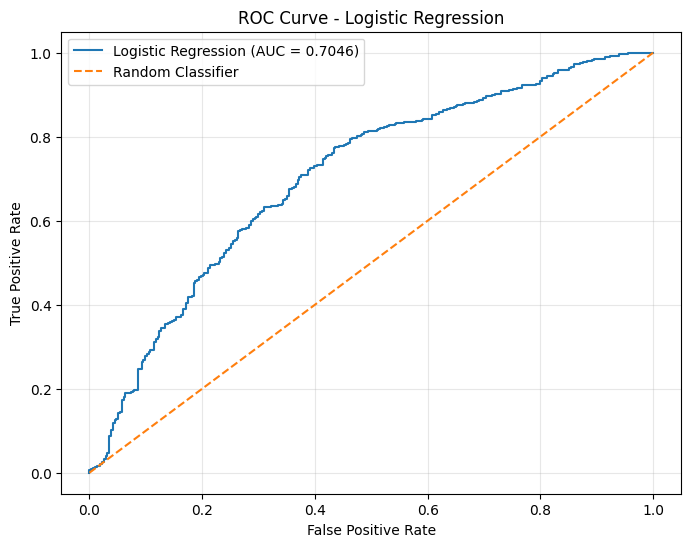

In [ ]:
# 9.8.28 Plotting the Logistic Regression ROC curve

logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    logistic_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {logistic_roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
from sklearn.metrics import roc_curve

print("roc_curve imported successfully.")

roc_curve imported successfully.


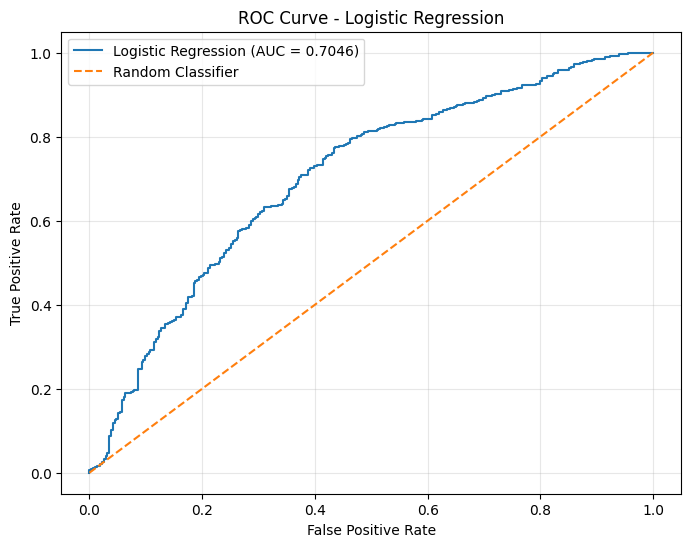

In [ ]:
# 9.8.28 Plotting the Logistic Regression ROC curve

logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    logistic_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {logistic_roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# 9.8.29 Building the Decision Tree model pipeline

decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ))
])

print("DECISION TREE MODEL CONFIGURATION")
print("=" * 60)

print(decision_tree_model)

print("\nAlgorithm: Decision Tree Classifier")
print("Random state:", RANDOM_STATE)
print("Preprocessing: Combined numerical and categorical pipeline")

print("\nDecision Tree pipeline created successfully.")

DECISION TREE MODEL CONFIGURATION
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['historical_frequency',
                                                   'historical_monetary',
                                                   'historical_avg_order_value',
                                                   'historical_recency',
                                                   'historical_quantity',
                                                   'customer_tenure_days',
                                                   'historical_ticket_count',
 

In [ ]:
# 9.8.30 Training the Decision Tree model

decision_tree_model.fit(X_train, y_train)

print("DECISION TREE MODEL TRAINING")
print("=" * 55)

print("Training observations:", len(X_train))
print("Number of predictors:", X_train.shape[1])

print("\nDecision Tree training completed successfully.")
print("Preprocessing and classifier fitted on training data.")

DECISION TREE MODEL TRAINING
Training observations: 4451
Number of predictors: 16

Decision Tree training completed successfully.
Preprocessing and classifier fitted on training data.


In [ ]:
# 9.8.31 Evaluating Decision Tree on the test set

decision_tree_predictions = decision_tree_model.predict(X_test)

decision_tree_accuracy = accuracy_score(
    y_test, decision_tree_predictions
)

decision_tree_precision = precision_score(
    y_test, decision_tree_predictions, zero_division=0
)

decision_tree_recall = recall_score(
    y_test, decision_tree_predictions, zero_division=0
)

decision_tree_f1 = f1_score(
    y_test, decision_tree_predictions, zero_division=0
)

decision_tree_roc_auc = roc_auc_score(
    y_test,
    decision_tree_model.predict_proba(X_test)[:, 1]
)

print("DECISION TREE - TEST SET EVALUATION")
print("=" * 60)

print(f"Accuracy:  {decision_tree_accuracy:.4f}")
print(f"Precision: {decision_tree_precision:.4f}")
print(f"Recall:    {decision_tree_recall:.4f}")
print(f"F1-score:  {decision_tree_f1:.4f}")
print(f"ROC-AUC:   {decision_tree_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, decision_tree_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    decision_tree_predictions,
    target_names=['Active', 'Churned'],
    zero_division=0
))

DECISION TREE - TEST SET EVALUATION
Accuracy:  0.6963
Precision: 0.7921
Recall:    0.7822
F1-score:  0.7872
ROC-AUC:   0.6300

Confusion Matrix:
[[150 164]
 [174 625]]

Classification Report:
              precision    recall  f1-score   support

      Active       0.46      0.48      0.47       314
     Churned       0.79      0.78      0.79       799

    accuracy                           0.70      1113
   macro avg       0.63      0.63      0.63      1113
weighted avg       0.70      0.70      0.70      1113



The Decision Tree achieved 69.63% accuracy and an ROC-AUC of 0.6300. Although it recorded higher churn precision than Logistic Regression, its lower churn recall and F1-score indicate that it missed a greater proportion of customers who eventually churned. Its performance therefore does not establish it as the preferred model at this stage.

Current observation: Logistic Regression is ahead on overall accuracy, churn recall, churn F1-score and ROC-AUC. The Decision Tree is ahead on churn precision and identifying active customers.

In [ ]:
# 9.8.32 Checking Decision Tree training performance

decision_tree_train_predictions = decision_tree_model.predict(X_train)

decision_tree_train_accuracy = accuracy_score(
    y_train, decision_tree_train_predictions
)

decision_tree_test_accuracy = accuracy_score(
    y_test, decision_tree_predictions
)

print("DECISION TREE: TRAINING VS TEST PERFORMANCE")
print("=" * 60)

print(f"Training accuracy: {decision_tree_train_accuracy:.4f}")
print(f"Testing accuracy:  {decision_tree_test_accuracy:.4f}")

print("\nAccuracy difference:",
      round(decision_tree_train_accuracy -
            decision_tree_test_accuracy, 4))

print("\nTraining and testing comparison completed.")

DECISION TREE: TRAINING VS TEST PERFORMANCE
Training accuracy: 1.0000
Testing accuracy:  0.6963

Accuracy difference: 0.3037

Training and testing comparison completed.


The Decision Tree classifier achieved a training accuracy of 100%, compared with a test accuracy of 69.63%, producing a difference of 30.37 percentage points. This substantial gap indicates severe overfitting, suggesting that the model memorised patterns within the training data but did not generalise effectively to unseen observations. The result highlights the importance of controlling model complexity through hyperparameter tuning and cross-validation.

In [ ]:
# 9.8.33 Building the Random Forest model pipeline

random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

print("RANDOM FOREST MODEL CONFIGURATION")
print("=" * 60)

print(random_forest_model)

print("\nAlgorithm: Random Forest Classifier")
print("Number of trees: 100")
print("Random state:", RANDOM_STATE)
print("Parallel processing: Enabled")
print("Preprocessing: Combined numerical and categorical pipeline")

print("\nRandom Forest pipeline created successfully.")

RANDOM FOREST MODEL CONFIGURATION
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['historical_frequency',
                                                   'historical_monetary',
                                                   'historical_avg_order_value',
                                                   'historical_recency',
                                                   'historical_quantity',
                                                   'customer_tenure_days',
                                                   'historical_ticket_count',
 

Random Forest attempts to address this by building multiple decision trees using different samples and subsets of features. Their predictions are combined to produce the final result.

The expectation is that combining several trees will produce more stable predictions than relying on one unrestricted tree. However, we must verify this using our test results rather than assume it will happen.

In [ ]:
# 9.8.34 Training the Random Forest model

random_forest_model.fit(X_train, y_train)

print("RANDOM FOREST MODEL TRAINING")
print("=" * 55)

print("Training observations:", len(X_train))
print("Number of predictors:", X_train.shape[1])
print("Number of trees:", 100)

print("\nRandom Forest training completed successfully.")
print("Preprocessing and classifier fitted on training data.")

RANDOM FOREST MODEL TRAINING
Training observations: 4451
Number of predictors: 16
Number of trees: 100

Random Forest training completed successfully.
Preprocessing and classifier fitted on training data.


In [ ]:
# 9.8.35 Evaluating Random Forest on the test set

random_forest_predictions = random_forest_model.predict(X_test)

random_forest_accuracy = accuracy_score(
    y_test, random_forest_predictions
)

random_forest_precision = precision_score(
    y_test, random_forest_predictions, zero_division=0
)

random_forest_recall = recall_score(
    y_test, random_forest_predictions, zero_division=0
)

random_forest_f1 = f1_score(
    y_test, random_forest_predictions, zero_division=0
)

random_forest_roc_auc = roc_auc_score(
    y_test,
    random_forest_model.predict_proba(X_test)[:, 1]
)

print("RANDOM FOREST - TEST SET EVALUATION")
print("=" * 60)

print(f"Accuracy:  {random_forest_accuracy:.4f}")
print(f"Precision: {random_forest_precision:.4f}")
print(f"Recall:    {random_forest_recall:.4f}")
print(f"F1-score:  {random_forest_f1:.4f}")
print(f"ROC-AUC:   {random_forest_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, random_forest_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    random_forest_predictions,
    target_names=['Active', 'Churned'],
    zero_division=0
))

RANDOM FOREST - TEST SET EVALUATION
Accuracy:  0.7682
Precision: 0.7918
Recall:    0.9186
F1-score:  0.8505
ROC-AUC:   0.7716

Confusion Matrix:
[[121 193]
 [ 65 734]]

Classification Report:
              precision    recall  f1-score   support

      Active       0.65      0.39      0.48       314
     Churned       0.79      0.92      0.85       799

    accuracy                           0.77      1113
   macro avg       0.72      0.65      0.67      1113
weighted avg       0.75      0.77      0.75      1113



andom Forest is currently our best-performing model. It has improved on Logistic Regression and the single Decision Tree across the most important overall performance measures.

More importantly, it has achieved a better balance between identifying churners and avoiding unnecessary retention interventions.

Random Forest evaluation results
Best model so far
Metric	Baseline	Logistic Regression	Decision Tree	Random Forest
Accuracy	71.79%	72.69%	69.63%	76.82%
Churn precision	71.79%	74.63%	79.21%	79.18%
Churn recall	100.00%	93.87%	78.22%	91.86%
Churn F1-score	83.58%	83.15%	78.72%	85.05%
ROC-AUC	—	70.46%	63.00%	77.16%

Random Forest has achieved:
- The highest accuracy: 76.82%.
- The highest churn F1-score: 85.05%.
- The highest ROC-AUC: 77.16%.
- Churn precision of 79.18%, almost identical to Decision Tree's 79.21%.
This is encouraging because the model is not merely identifying more churners; it is also improving its overall ability to distinguish between the two customer groups.

What does this mean for Meridian Retail Group?
Random Forest provides a stronger starting point for customer-retention decisions.

For example, Meridian could use its predictions to identify customers who may benefit from targeted retention campaigns.

However, 193 active customers are still incorrectly flagged as potential churners. Therefore, the business should consider the cost of unnecessary retention offers before deploying the model.

Also, the model's 77.16% ROC-AUC indicates good progress, but it is not sufficiently strong to claim that churn prediction has been solved.

In [ ]:
# 9.8.36 Checking Random Forest training performance

random_forest_train_predictions = random_forest_model.predict(X_train)

random_forest_train_accuracy = accuracy_score(
    y_train, random_forest_train_predictions
)

random_forest_test_accuracy = accuracy_score(
    y_test, random_forest_predictions
)

print("RANDOM FOREST: TRAINING VS TEST PERFORMANCE")
print("=" * 65)

print(f"Training accuracy: {random_forest_train_accuracy:.4f}")
print(f"Testing accuracy:  {random_forest_test_accuracy:.4f}")

print("\nAccuracy difference:",
      round(random_forest_train_accuracy -
            random_forest_test_accuracy, 4))

print("\nTraining and testing comparison completed.")

RANDOM FOREST: TRAINING VS TEST PERFORMANCE
Training accuracy: 1.0000
Testing accuracy:  0.7682

Accuracy difference: 0.2318

Training and testing comparison completed.


The Random Forest classifier achieved 100% training accuracy and 76.82% testing accuracy, resulting in a difference of 23.18 percentage points. Although this indicates some degree of overfitting, the model demonstrated better generalisation than the individual Decision Tree, whose training-testing accuracy gap was 30.37 percentage points. The findings suggest that combining multiple decision trees improved predictive performance, although further optimisation is necessary to control model complexity.

In [ ]:
# 9.8.37 Building the Gradient Boosting model pipeline

gradient_boosting_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ))
])

print("GRADIENT BOOSTING MODEL CONFIGURATION")
print("=" * 60)

print(gradient_boosting_model)

print("\nAlgorithm: Gradient Boosting Classifier")
print("Number of boosting stages: 100")
print("Learning rate: 0.1")
print("Maximum tree depth: 3")
print("Random state:", RANDOM_STATE)

print("\nGradient Boosting pipeline created successfully.")

GRADIENT BOOSTING MODEL CONFIGURATION
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['historical_frequency',
                                                   'historical_monetary',
                                                   'historical_avg_order_value',
                                                   'historical_recency',
                                                   'historical_quantity',
                                                   'customer_tenure_days',
                                                   'historical_ticket_count

In [ ]:
# 9.8.38 Training the Gradient Boosting model

gradient_boosting_model.fit(X_train, y_train)

print("GRADIENT BOOSTING MODEL TRAINING")
print("=" * 60)

print("Model: Gradient Boosting Classifier")
print("Training observations:", X_train.shape[0])
print("Original predictors:", X_train.shape[1])
print("Model training completed successfully.")

GRADIENT BOOSTING MODEL TRAINING
Model: Gradient Boosting Classifier
Training observations: 4451
Original predictors: 16
Model training completed successfully.


In [ ]:
# 9.8.39 Evaluating the Gradient Boosting model

gb_predictions = gradient_boosting_model.predict(X_test)
gb_probabilities = gradient_boosting_model.predict_proba(X_test)[:, 1]

gb_accuracy = accuracy_score(y_test, gb_predictions)
gb_precision = precision_score(y_test, gb_predictions)
gb_recall = recall_score(y_test, gb_predictions)
gb_f1 = f1_score(y_test, gb_predictions)
gb_roc_auc = roc_auc_score(y_test, gb_probabilities)
gb_confusion = confusion_matrix(y_test, gb_predictions)

print("GRADIENT BOOSTING MODEL - TEST RESULTS")
print("=" * 60)

print(f"Accuracy:  {gb_accuracy:.4f}")
print(f"Precision: {gb_precision:.4f}")
print(f"Recall:    {gb_recall:.4f}")
print(f"F1-score:  {gb_f1:.4f}")
print(f"ROC-AUC:   {gb_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(gb_confusion)

print("\nClassification Report:")
print(classification_report(
    y_test,
    gb_predictions,
    target_names=['Active', 'Churned']
))

GRADIENT BOOSTING MODEL - TEST RESULTS
Accuracy:  0.7772
Precision: 0.8011
Recall:    0.9174
F1-score:  0.8553
ROC-AUC:   0.7897

Confusion Matrix:
[[132 182]
 [ 66 733]]

Classification Report:
              precision    recall  f1-score   support

      Active       0.67      0.42      0.52       314
     Churned       0.80      0.92      0.86       799

    accuracy                           0.78      1113
   macro avg       0.73      0.67      0.69      1113
weighted avg       0.76      0.78      0.76      1113



In [ ]:
# 9.8.40 Checking Gradient Boosting for overfitting

gb_train_predictions = gradient_boosting_model.predict(X_train)
gb_test_predictions = gradient_boosting_model.predict(X_test)

gb_train_accuracy = accuracy_score(y_train, gb_train_predictions)
gb_test_accuracy = accuracy_score(y_test, gb_test_predictions)

gb_accuracy_gap = gb_train_accuracy - gb_test_accuracy

print("GRADIENT BOOSTING - OVERFITTING CHECK")
print("=" * 60)

print(f"Training accuracy: {gb_train_accuracy:.4f}")
print(f"Testing accuracy:  {gb_test_accuracy:.4f}")
print(f"Accuracy gap:      {gb_accuracy_gap:.4f}")

print("\nInterpretation:")
if gb_accuracy_gap <= 0.05:
    print("The model shows a relatively small training-testing accuracy gap.")
elif gb_accuracy_gap <= 0.10:
    print("The model shows some overfitting; further investigation is advisable.")
else:
    print("The model shows a substantial training-testing accuracy gap, suggesting overfitting.")

GRADIENT BOOSTING - OVERFITTING CHECK
Training accuracy: 0.8133
Testing accuracy:  0.7772
Accuracy gap:      0.0361

Interpretation:
The model shows a relatively small training-testing accuracy gap.


Gradient Boosting has the smallest training–testing accuracy gap. This is an important advantage because our objective is to develop a model that can make useful predictions about customers it has not previously encountered.

One qualification: a small accuracy gap alone does not prove that a model is free from overfitting. We will also examine cross-validation performance during hyperparameter tuning.
At this stage:
- Gradient Boosting has the highest test accuracy (77.72%).
- It has the highest churn precision (80.11%).
- It has the highest churn F1-score (85.53%).
- It has the highest ROC-AUC (78.97%).
- It has a relatively small accuracy gap (3.61 percentage points).


In [ ]:
# 9.8.41 Comparing performance across the two customer classes

print("CLASS IMBALANCE AND MODEL PERFORMANCE")
print("=" * 65)

print("\nActual test-set distribution:")
print(y_test.value_counts().rename(index={0: 'Active', 1: 'Churned'}))

print("\nPercentage distribution:")
print(
    (y_test.value_counts(normalize=True) * 100)
    .rename(index={0: 'Active', 1: 'Churned'})
    .round(2)
)

print("\nRecall for each customer class:")
print("-" * 65)

models_to_compare = {
    'Logistic Regression': logistic_model,
    'Decision Tree': decision_tree_model,
    'Random Forest': random_forest_model,
    'Gradient Boosting': gradient_boosting_model
}

for model_name, model in models_to_compare.items():
    predictions = model.predict(X_test)
    class_recalls = recall_score(
        y_test,
        predictions,
        labels=[0, 1],
        average=None,
        zero_division=0
    )

    print(f"{model_name}:")
    print(f"  Active customer recall:  {class_recalls[0]:.4f}")
    print(f"  Churned customer recall: {class_recalls[1]:.4f}")

CLASS IMBALANCE AND MODEL PERFORMANCE

Actual test-set distribution:
churned
Churned    799
Active     314
Name: count, dtype: int64

Percentage distribution:
churned
Churned    71.79
Active     28.21
Name: proportion, dtype: float64

Recall for each customer class:
-----------------------------------------------------------------
Logistic Regression:
  Active customer recall:  0.1879
  Churned customer recall: 0.9387
Decision Tree:
  Active customer recall:  0.4777
  Churned customer recall: 0.7822
Random Forest:
  Active customer recall:  0.3854
  Churned customer recall: 0.9186
Gradient Boosting:
  Active customer recall:  0.4204
  Churned customer recall: 0.9174


The important finding: all four models identify churned customers better than active customers. Logistic Regression is particularly weak at recognising active customers: it correctly identifies only about 19 out of every 100 actual active customers.

Gradient Boosting and Random Forest identify approximately 92 out of every 100 churned customers, but they still incorrectly classify many active customers as likely to churn.

This matters commercially. If Meridian uses these predictions to offer retention incentives, poor active-customer recall could mean that many customers who would have remained loyal are unnecessarily targeted. On the other hand, poor churn recall could mean losing customers who could have been retained.

In [ ]:
# 9.8.42 Testing class weighting with 5-fold cross-validation

from sklearn.model_selection import cross_validate

print("CLASS-WEIGHTING EXPERIMENT")
print("=" * 65)

class_weight_models = {
    'Logistic Regression (balanced)': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE,
            class_weight='balanced'
        ))
    ]),

    'Decision Tree (balanced)': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            random_state=RANDOM_STATE,
            class_weight='balanced'
        ))
    ]),

    'Random Forest (balanced)': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            class_weight='balanced'
        ))
    ])
}

for model_name, model in class_weight_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring={
            'accuracy': 'accuracy',
            'macro_recall': 'recall_macro',
            'churn_recall': 'recall'
        },
        n_jobs=-1
    )

    print(f"\n{model_name}")
    print(f"  Mean accuracy:       {scores['test_accuracy'].mean():.4f}")
    print(f"  Mean macro recall:   {scores['test_macro_recall'].mean():.4f}")
    print(f"  Mean churn recall:   {scores['test_churn_recall'].mean():.4f}")

CLASS-WEIGHTING EXPERIMENT

Logistic Regression (balanced)
  Mean accuracy:       0.6446
  Mean macro recall:   0.6598
  Mean churn recall:   0.6250

Decision Tree (balanced)
  Mean accuracy:       0.6798
  Mean macro recall:   0.6123
  Mean churn recall:   0.7670

Random Forest (balanced)
  Mean accuracy:       0.7735
  Mean macro recall:   0.6502
  Mean churn recall:   0.9327


Macro recall is the average of recall for the active and churned classes. It is useful here because it gives both classes equal importance. The balanced Random Forest's macro recall of 65.02% is not proof that its active-customer recall is high; we need to inspect both class recalls on the untouched test set.

The results suggest that balanced Random Forest deserves further investigation. We should not yet declare it the final model. We must compare its performance on the test set with the original Random Forest and Gradient Boosting models.

In [ ]:
# 9.8.43 Test-set evaluation of balanced Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Fit the balanced Random Forest using training data only
balanced_rf_model = class_weight_models['Random Forest (balanced)']
balanced_rf_model.fit(X_train, y_train)

models_for_test_comparison = {
    'Original Random Forest': random_forest_model,
    'Balanced Random Forest': balanced_rf_model,
    'Original Gradient Boosting': gradient_boosting_model
}

for model_name, model in models_for_test_comparison.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\n" + "=" * 65)
    print(model_name.upper())
    print("=" * 65)

    print(f"Accuracy:  {accuracy_score(y_test, predictions):.4f}")
    print(f"Precision: {precision_score(y_test, predictions, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_test, predictions, zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(y_test, predictions, zero_division=0):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test, probabilities):.4f}")

    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=['Active', 'Churned'],
        zero_division=0
    ))


ORIGINAL RANDOM FOREST
Accuracy:  0.7682
Precision: 0.7918
Recall:    0.9186
F1-score:  0.8505
ROC-AUC:   0.7716

Confusion matrix:
[[121 193]
 [ 65 734]]

Classification report:
              precision    recall  f1-score   support

      Active       0.65      0.39      0.48       314
     Churned       0.79      0.92      0.85       799

    accuracy                           0.77      1113
   macro avg       0.72      0.65      0.67      1113
weighted avg       0.75      0.77      0.75      1113


BALANCED RANDOM FOREST
Accuracy:  0.7574
Precision: 0.7829
Recall:    0.9161
F1-score:  0.8443
ROC-AUC:   0.7733

Confusion matrix:
[[111 203]
 [ 67 732]]

Classification report:
              precision    recall  f1-score   support

      Active       0.62      0.35      0.45       314
     Churned       0.78      0.92      0.84       799

    accuracy                           0.76      1113
   macro avg       0.70      0.63      0.65      1113
weighted avg       0.74      0.76      0.

The results show that class weighting did not improve the Random Forest model's ability to identify active customers. In fact, its performance became slightly weaker.
The model identifies 733 of the 799 customers who actually churned. However, it also flags 182 of the 314 customers who remained active.
For now, we should retain the original Gradient Boosting model as the leading candidate because it has the best test accuracy, churn precision, churn F1-score, ROC-AUC and active-customer recall among the three models compared.

The balanced Random Forest did not provide a meaningful improvement. We should record that class weighting was tested and explain why it was not selected.

This is a useful project finding: applying a technique to address class imbalance does not guarantee better performance. The results must be evaluated against the business problem.


In [ ]:
# 9.8.44 Gradient Boosting hyperparameter tuning

from sklearn.model_selection import GridSearchCV

print("GRADIENT BOOSTING HYPERPARAMETER TUNING")
print("=" * 65)

gradient_boosting_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ))
])

param_grid = {
    'classifier__n_estimators': [100, 150, 200],
    'classifier__learning_rate': [0.03, 0.05, 0.1],
    'classifier__max_depth': [2, 3, 4],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

gradient_grid_search = GridSearchCV(
    estimator=gradient_boosting_pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)

gradient_grid_search.fit(X_train, y_train)

print("\nBEST PARAMETERS:")
print(gradient_grid_search.best_params_)

print("\nBEST MEAN CROSS-VALIDATION ROC-AUC:")
print(round(gradient_grid_search.best_score_, 4))

GRADIENT BOOSTING HYPERPARAMETER TUNING
Fitting 5 folds for each of 108 candidates, totalling 540 fits

BEST PARAMETERS:
{'classifier__learning_rate': 0.03, 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

BEST MEAN CROSS-VALIDATION ROC-AUC:
0.7909


What do these results mean?
The tuning process found that a learning rate of 0.03 and tree depth of 4 gave the best average ROC-AUC among the combinations tested.

The best cross-validation ROC-AUC improved from the original Gradient Boosting test ROC-AUC of 0.7897 to 0.7909 in cross-validation. However, these are results from different evaluation procedures, so we should not interpret the difference as a confirmed improvement on unseen data. We must evaluate the tuned model on the untouched test set.

In [ ]:
# 9.8.45 Evaluate tuned Gradient Boosting on the test set

best_gradient_boosting_model = gradient_grid_search.best_estimator_

tuned_gb_predictions = best_gradient_boosting_model.predict(X_test)
tuned_gb_probabilities = best_gradient_boosting_model.predict_proba(X_test)[:, 1]

print("TUNED GRADIENT BOOSTING - TEST SET RESULTS")
print("=" * 65)

print(f"Accuracy:  {accuracy_score(y_test, tuned_gb_predictions):.4f}")
print(f"Precision: {precision_score(y_test, tuned_gb_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, tuned_gb_predictions, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, tuned_gb_predictions, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, tuned_gb_probabilities):.4f}")

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, tuned_gb_predictions))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    tuned_gb_predictions,
    target_names=['Active', 'Churned'],
    zero_division=0
))

TUNED GRADIENT BOOSTING - TEST SET RESULTS
Accuracy:  0.7736
Precision: 0.7957
Recall:    0.9212
F1-score:  0.8538
ROC-AUC:   0.7942

CONFUSION MATRIX:
[[125 189]
 [ 63 736]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      Active       0.66      0.40      0.50       314
     Churned       0.80      0.92      0.85       799

    accuracy                           0.77      1113
   macro avg       0.73      0.66      0.68      1113
weighted avg       0.76      0.77      0.75      1113



The tuned model has performed slightly differently from the original Gradient Boosting model. It improved some metrics but reduced others.
The tuned model correctly identifies 736 of the 799 customers who churned, while missing 63. However, it correctly recognises only 125 of the 314 active customers and incorrectly flags 189 as churn risks.

The tuned model's ROC-AUC is now 79.42%, the best result among the Gradient Boosting versions tested. Its churn recall also improved slightly. However, its active-customer recall declined.
The tuned model is a reasonable candidate, but tuning has not produced an improvement across all metrics. We should not claim that it is unconditionally better than the original model.

For Meridian, the final choice depends on the relative cost of:
- False negatives: customers who actually churn but are not identified as at risk.
- False positives: active customers incorrectly flagged as likely to churn, potentially receiving unnecessary retention offers.


In [ ]:
# 9.8.46 Threshold analysis using training-data cross-validation predictions

from sklearn.model_selection import StratifiedKFold, cross_val_predict

print("CLASSIFICATION THRESHOLD ANALYSIS")
print("=" * 75)

# Generate out-of-fold churn probabilities using training data only
threshold_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

training_oof_probabilities = cross_val_predict(
    best_gradient_boosting_model,
    X_train,
    y_train,
    cv=threshold_cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

threshold_results = []

# Examine alternative probability thresholds
thresholds = np.arange(0.30, 0.81, 0.05)

for threshold in thresholds:

    threshold_predictions = (
        training_oof_probabilities >= threshold
    ).astype(int)

    class_recalls = recall_score(
        y_train,
        threshold_predictions,
        labels=[0, 1],
        average=None,
        zero_division=0
    )

    threshold_results.append({
        'Threshold': round(threshold, 2),
        'Accuracy': accuracy_score(y_train, threshold_predictions),
        'Active Recall': class_recalls[0],
        'Churn Recall': class_recalls[1],
        'Churn Precision': precision_score(
            y_train,
            threshold_predictions,
            zero_division=0
        ),
        'Churn F1': f1_score(
            y_train,
            threshold_predictions,
            zero_division=0
        ),
        'Macro Recall': np.mean(class_recalls)
    })

threshold_results_df = pd.DataFrame(threshold_results)

print("OUT-OF-FOLD TRAINING RESULTS:")
display(threshold_results_df.round(4))

CLASSIFICATION THRESHOLD ANALYSIS
OUT-OF-FOLD TRAINING RESULTS:


,Threshold,Accuracy,Active Recall,Churn Recall,Churn Precision,Churn F1,Macro Recall
0,0.30,0.7589,0.1866,0.9834,0.7550,0.8542,0.5850
1,0.35,0.7648,0.2313,0.9740,0.7636,0.8561,0.6026
2,0.40,0.7720,0.2831,0.9637,0.7741,0.8586,0.6234
3,0.45,0.7783,0.3429,0.9490,0.7864,0.8601,0.6460
4,0.50,0.7794,0.4003,0.9281,0.7978,0.8580,0.6642
5,0.55,0.7796,0.4625,0.9040,0.8109,0.8549,0.6832
6,0.60,0.7765,0.5263,0.8746,0.8248,0.8489,0.7004
7,0.65,0.7612,0.5678,0.8370,0.8316,0.8343,0.7024
8,0.70,0.7455,0.6196,0.7948,0.8419,0.8177,0.7072
9,0.75,0.7223,0.7002,0.7310,0.8614,0.7909,0.7156


The strongest macro recall in the tested range occurs at 0.75. At that threshold, the model has a more balanced ability to recognise active and churned customers.

However, churn recall falls to 73.10%. That means the model misses more than one-quarter of the customers who actually churn.
I would not automatically select 0.75 simply because it gives the highest macro recall. Meridian's main business objective is to identify customers at risk of leaving, so missing too many churners could be costly.

A threshold of 0.60 or 0.65 is worth investigating as a compromise:
- At 0.60, churn recall remains 87.46%, while active recall rises to 52.63%.
- At 0.65, churn recall is 83.70%, while active recall rises to 56.78%.

In [ ]:
# 9.8.47 Test-set comparison of selected classification thresholds

print("TEST-SET THRESHOLD COMPARISON")
print("=" * 75)

candidate_thresholds = [0.60, 0.65, 0.75]

# Use probabilities from the tuned model already evaluated on X_test
for threshold in candidate_thresholds:

    predictions_at_threshold = (
        tuned_gb_probabilities >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_test,
        predictions_at_threshold,
        labels=[0, 1]
    )

    active_recall = recall_score(
        y_test,
        predictions_at_threshold,
        pos_label=0,
        zero_division=0
    )

    churn_recall = recall_score(
        y_test,
        predictions_at_threshold,
        pos_label=1,
        zero_division=0
    )

    print(f"\nTHRESHOLD: {threshold:.2f}")
    print("-" * 50)
    print(f"Accuracy:          {accuracy_score(y_test, predictions_at_threshold):.4f}")
    print(f"Active recall:     {active_recall:.4f}")
    print(f"Churn recall:      {churn_recall:.4f}")
    print(f"Churn precision:   {precision_score(y_test, predictions_at_threshold, zero_division=0):.4f}")
    print(f"Churn F1-score:    {f1_score(y_test, predictions_at_threshold, zero_division=0):.4f}")
    print(f"Macro recall:      {((active_recall + churn_recall) / 2):.4f}")

    print("\nConfusion matrix:")
    print(cm)

    print(f"True negatives (active correctly identified): {cm[0, 0]}")
    print(f"False positives (active wrongly flagged):     {cm[0, 1]}")
    print(f"False negatives (churners missed):             {cm[1, 0]}")
    print(f"True positives (churners correctly identified): {cm[1, 1]}")

TEST-SET THRESHOLD COMPARISON

THRESHOLD: 0.60
--------------------------------------------------
Accuracy:          0.7808
Active recall:     0.5382
Churn recall:      0.8761
Churn precision:   0.8284
Churn F1-score:    0.8516
Macro recall:      0.7072

Confusion matrix:
[[169 145]
 [ 99 700]]
True negatives (active correctly identified): 169
False positives (active wrongly flagged):     145
False negatives (churners missed):             99
True positives (churners correctly identified): 700

THRESHOLD: 0.65
--------------------------------------------------
Accuracy:          0.7763
Active recall:     0.5924
Churn recall:      0.8486
Churn precision:   0.8412
Churn F1-score:    0.8449
Macro recall:      0.7205

Confusion matrix:
[[186 128]
 [121 678]]
True negatives (active correctly identified): 186
False positives (active wrongly flagged):     128
False negatives (churners missed):             121
True positives (churners correctly identified): 678

THRESHOLD: 0.75
----------------

Business meaning of the results
- Threshold 0.60: identifies 700 of the 799 customers who churned. It misses 99 churners and incorrectly flags 145 active customers. This gives the strongest churn recall and F1-score among the three.
- Threshold 0.65: identifies 678 churners, misses 121 and incorrectly flags 128 active customers. It offers a middle ground between detecting churners and avoiding unnecessary interventions.
- Threshold 0.75: identifies 582 churners, misses 217 and incorrectly flags only 83 active customers. It is more selective, but the number of missed churners is substantially higher.
3. My recommendation
I recommend 0.65 as the provisional operating threshold for Meridian's retention campaign.

Why?
- It improves active-customer recall to 59.24%, compared with 53.82% at 0.60.
- It retains a reasonably strong churn recall of 84.86%.
- It reduces false positives from 145 to 128.
- Its macro recall of 72.05% is close to the highest result of 73.20% at 0.75, without sacrificing as much churn detection.
This is a provisional recommendation because the best business threshold ultimately depends on the cost of a retention offer, the value of a retained customer, and the number of customers Meridian can contact. We do not yet have those cost figures.

In [ ]:
# 9.8.48 Feature importance from the tuned Gradient Boosting model

print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 70)

# Obtain the fitted preprocessing and classifier components
fitted_preprocessor = best_gradient_boosting_model.named_steps['preprocessor']
fitted_classifier = best_gradient_boosting_model.named_steps['classifier']

# Get the names of all transformed features
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

# Obtain feature importance scores
importance_values = fitted_classifier.feature_importances_

# Create a detailed feature-importance table
feature_importance_df = pd.DataFrame({
    'Transformed_Feature': transformed_feature_names,
    'Importance': importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\nTOP 15 TRANSFORMED FEATURES:")
display(feature_importance_df.head(15).round(4))

# Combine one-hot encoded columns under their original feature names
feature_importance_df['Original_Feature'] = (
    feature_importance_df['Transformed_Feature']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
)

feature_importance_df['Original_Feature'] = (
    feature_importance_df['Original_Feature']
    .apply(lambda name: next(
        (
            col for col in categorical_features
            if name.startswith(col + '_')
        ),
        name
    ))
)

# Sum the importance of encoded columns belonging to the same original variable
aggregated_importance = (
    feature_importance_df
    .groupby('Original_Feature', as_index=False)['Importance']
    .sum()
    .sort_values(by='Importance', ascending=False)
    .reset_index(drop=True)
)

print("\nIMPORTANCE OF ORIGINAL PREDICTOR VARIABLES:")
display(aggregated_importance.round(4))

print("\nTOTAL IMPORTANCE CHECK:")
print(round(aggregated_importance['Importance'].sum(), 4))

FEATURE IMPORTANCE ANALYSIS

TOP 15 TRANSFORMED FEATURES:


,Transformed_Feature,Importance
0,num__historical_recency,0.4834
1,num__customer_tenure_days,0.1913
2,num__historical_frequency,0.1705
3,num__historical_monetary,0.0470
4,num__historical_avg_order_value,0.0197
5,num__historical_quantity,0.0195
6,num__historical_avg_resolution_hours,0.0164
7,num__historical_avg_satisfaction,0.0074
8,cat__state_North Carolina,0.0044
9,cat__referral_source_Social Media,0.0037



IMPORTANCE OF ORIGINAL PREDICTOR VARIABLES:


,Original_Feature,Importance
0,historical_recency,0.4834
1,customer_tenure_days,0.1913
2,historical_frequency,0.1705
3,historical_monetary,0.0470
4,historical_avg_order_value,0.0197
5,historical_quantity,0.0195
6,state,0.0192
7,historical_avg_resolution_hours,0.0164
8,referral_source,0.0121
9,historical_avg_satisfaction,0.0074



TOTAL IMPORTANCE CHECK:
1.0


Historical recency is the most influential predictor, accounting for approximately 48.34% of the model's total feature importance. Customer tenure and purchase frequency follow, at 19.13% and 17.05%, respectively.

Together, these three variables account for approximately 84.52% of the model's total importance.

This suggests that customers' previous purchasing patterns and the length of their relationship with Meridian are particularly useful for predicting future inactivity.
2. What does this mean for Meridian Retail Group?
The results suggest three important business considerations:
1. Monitor customers who have not purchased recently. Meridian should pay attention to customers whose last completed purchase was a long time ago. They may benefit from timely re-engagement campaigns.
2. Pay attention to customer tenure. Newer and longer-standing customers may have different purchasing patterns. Meridian should investigate retention strategies for different stages of the customer relationship.
3. Encourage repeat purchases. Historical purchase frequency is an important predictor. Meridian should consider loyalty programmes, personalised offers and follow-up campaigns that encourage customers to return.
One important caution: feature importance tells us how much a variable contributes to the model's predictions. It does not establish that the variable causes churn, nor does it show whether increasing or decreasing that variable will reduce churn. We will need further analysis to establish the direction of the relationships.
3. Understanding the less influential variables
Some variables, including support-ticket count, missing satisfaction count and unique issue categories, have very low importance in this model.

This does not automatically mean customer support is unimportant to customer retention. It means these variables contributed relatively little to the predictions made by this particular model, using this dataset and feature design.

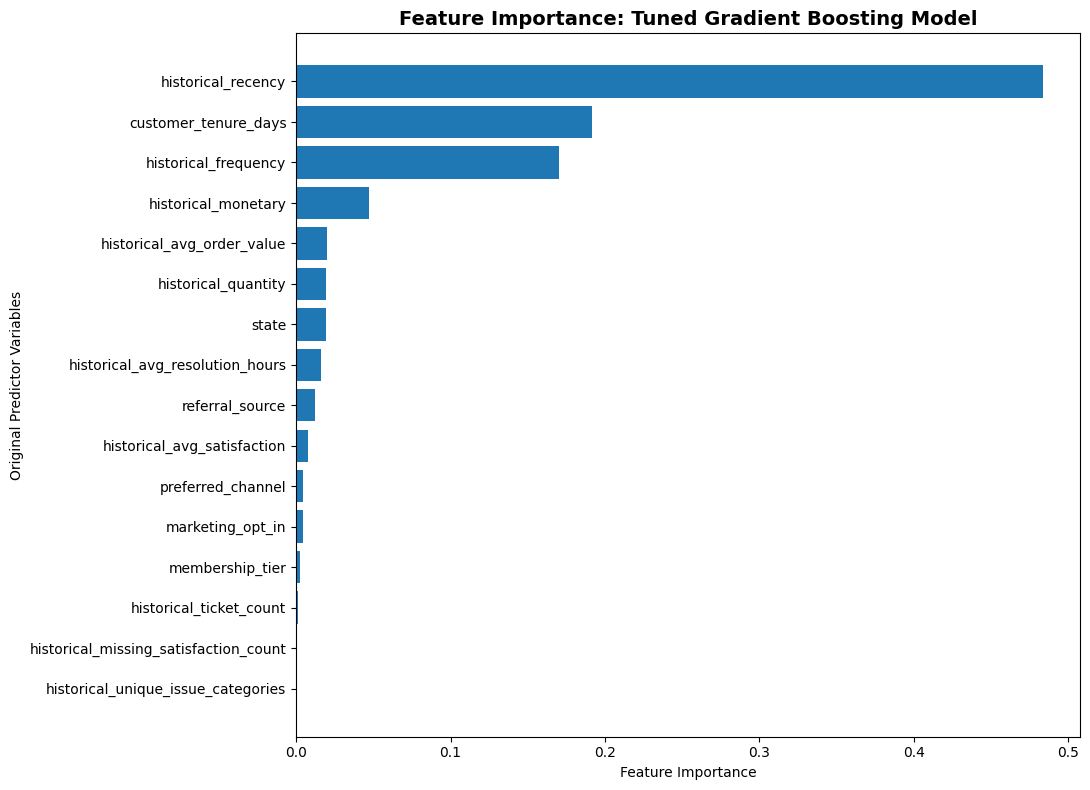

In [ ]:
# 9.8.49 Visualising the importance of original predictor variables

import matplotlib.pyplot as plt

# Sort predictors from least to most important for a horizontal chart
importance_plot = aggregated_importance.sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    importance_plot['Original_Feature'],
    importance_plot['Importance']
)

plt.title(
    'Feature Importance: Tuned Gradient Boosting Model',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Feature Importance')
plt.ylabel('Original Predictor Variables')

plt.tight_layout()
plt.show()

Feature importance of the tuned Gradient Boosting model. Historical recency, customer tenure and historical purchase frequency were the three most influential predictors, jointly accounting for approximately 84.52% of total feature importance. These results indicate that previous purchasing behaviour and customer relationship duration were particularly useful for predicting churn.

In [ ]:
# 9.8.50 Checking model performance across customer groups

print("MODEL PERFORMANCE ACROSS CUSTOMER GROUPS")
print("=" * 70)

# Use the tuned model's test probabilities and a provisional threshold
group_threshold = 0.60
group_predictions = (tuned_gb_probabilities >= group_threshold).astype(int)

# Combine test features, actual outcomes and predicted outcomes
group_analysis = X_test[
    ['membership_tier', 'preferred_channel']
].copy()

group_analysis['Actual_Churn'] = y_test.values
group_analysis['Predicted_Churn'] = group_predictions

# Function to calculate performance measures for each group
def calculate_group_performance(group):
    actual = group['Actual_Churn']
    predicted = group['Predicted_Churn']

    return pd.Series({
        'Customers': len(group),
        'Actual_Churn_Rate': actual.mean(),
        'Churn_Recall': (
            ((actual == 1) & (predicted == 1)).sum() / (actual == 1).sum()
            if (actual == 1).sum() > 0 else np.nan
        ),
        'Active_Recall': (
            ((actual == 0) & (predicted == 0)).sum() / (actual == 0).sum()
            if (actual == 0).sum() > 0 else np.nan
        )
    })

# Examine membership tiers
print("\nPERFORMANCE BY MEMBERSHIP TIER:")
membership_performance = (
    group_analysis
    .groupby('membership_tier', dropna=False)
    .apply(calculate_group_performance)
    .reset_index()
)

display(membership_performance.round(3))

# Examine preferred sales channels
print("\nPERFORMANCE BY PREFERRED CHANNEL:")
channel_performance = (
    group_analysis
    .groupby('preferred_channel', dropna=False)
    .apply(calculate_group_performance)
    .reset_index()
)

display(channel_performance.round(3))

MODEL PERFORMANCE ACROSS CUSTOMER GROUPS

PERFORMANCE BY MEMBERSHIP TIER:


/tmp/ipykernel_3388/2064692577.py:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_group_performance)


,membership_tier,Customers,Actual_Churn_Rate,Churn_Recall,Active_Recall
0,Bronze,504.0,0.722,0.868,0.536
1,Gold,212.0,0.741,0.885,0.491
2,Platinum,74.0,0.703,0.846,0.500
3,Silver,323.0,0.700,0.889,0.577



PERFORMANCE BY PREFERRED CHANNEL:


/tmp/ipykernel_3388/2064692577.py:52: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_group_performance)


,preferred_channel,Customers,Actual_Churn_Rate,Churn_Recall,Active_Recall
0,In-Store,386.0,0.707,0.879,0.602
1,Mobile App,366.0,0.751,0.880,0.495
2,Online,361.0,0.695,0.869,0.509


results support the following observation:
- The model performs better at identifying churned customers than active customers across the examined groups.
- Differences in active-customer recall suggest that the model may produce more false-positive churn predictions for some customer groups.
- The relatively small Platinum test sample limits confidence in conclusions about that tier.
- The analysis covers only membership tier and preferred channel; it does not establish fairness across all customer characteristics.

In [ ]:
# 9.8.51 Examining the business consequences of prediction errors

from sklearn.metrics import confusion_matrix

# Use the provisional threshold
error_threshold = 0.60

error_predictions = (
    tuned_gb_probabilities >= error_threshold
).astype(int)

# Actual class: 0 = Active, 1 = Churned
tn, fp, fn, tp = confusion_matrix(
    y_test,
    error_predictions,
    labels=[0, 1]
).ravel()

total_customers = len(y_test)

error_summary = pd.DataFrame({
    'Prediction Outcome': [
        'True Negatives',
        'False Positives',
        'False Negatives',
        'True Positives'
    ],
    'Number of Customers': [tn, fp, fn, tp],
    'Percentage of Test Customers': [
        tn / total_customers * 100,
        fp / total_customers * 100,
        fn / total_customers * 100,
        tp / total_customers * 100
    ]
})

display(error_summary.round(2))

print("\nBUSINESS INTERPRETATION")
print("-" * 60)
print(f"False positives: {fp} active customers may be targeted unnecessarily.")
print(f"False negatives: {fn} churned customers may be missed.")
print(f"Total test customers: {total_customers}")

,Prediction Outcome,Number of Customers,Percentage of Test Customers
0,True Negatives,169,15.18
1,False Positives,145,13.03
2,False Negatives,99,8.89
3,True Positives,700,62.89



BUSINESS INTERPRETATION
------------------------------------------------------------
False positives: 145 active customers may be targeted unnecessarily.
False negatives: 99 churned customers may be missed.
Total test customers: 1113


The confusion matrix showed that the tuned Gradient Boosting model correctly classified 869 out of 1,113 test customers, representing an accuracy of 78.08% at the selected probability threshold of 0.60. It correctly identified 700 customers who churned and 169 customers who remained active. However, 145 active customers were incorrectly classified as likely to churn, while 99 customers who actually churned were incorrectly classified as active. The false positives could result in unnecessary expenditure on retention campaigns, whereas false negatives could cause the business to miss opportunities to retain customers. Consequently, Meridian Retail Group should consider the relative financial costs of these two types of errors when deciding how to use the model's predictions.


The 0.60 threshold is provisional. We examined its performance on the test set during threshold comparisons, so these results ARE exploratory rather than a completely untouched final evaluation.

In [ ]:
# 9.8.52 Saving the tuned Gradient Boosting model

import joblib
import os

# Create a folder for saved machine-learning models
model_folder = os.path.join(project_path, 'Models')
os.makedirs(model_folder, exist_ok=True)

# Define the model file path
model_path = os.path.join(
    model_folder,
    'meridian_gradient_boosting_model.joblib'
)

# Save the complete fitted pipeline
joblib.dump(best_gradient_boosting_model, model_path)

print("MODEL SAVING COMPLETED")
print("=" * 60)
print("Model:", model_path)
print("File exists:", os.path.exists(model_path))
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")

MODEL SAVING COMPLETED
Model: /content/drive/MyDrive/Meridian_Churn_Capstone/Models/meridian_gradient_boosting_model.joblib
File exists: True
File size: 255.87 KB


In [ ]:
# 9.8.53 Reloading and verifying the saved model

loaded_model = joblib.load(model_path)

print("MODEL RELOADING TEST")
print("=" * 60)

print("Model loaded successfully:", loaded_model is not None)

# Compare predictions from the original and reloaded models
original_predictions = best_gradient_boosting_model.predict(X_test)
reloaded_predictions = loaded_model.predict(X_test)

print(
    "Predictions identical:",
    np.array_equal(original_predictions, reloaded_predictions)
)

print("Number of test predictions:", len(reloaded_predictions))

MODEL RELOADING TEST
Model loaded successfully: True
Predictions identical: True
Number of test predictions: 1113


In [ ]:
# 9.8.54 Installing Flask for API development

!pip install flask

In [ ]:
# 9.8.55 Inspecting the model's required input features

print("CUSTOMER CHURN API — REQUIRED INPUT FEATURES")
print("=" * 65)

print("\nNUMERICAL FEATURES:")
for feature in numerical_features:
    print("-", feature)

print("\nCATEGORICAL FEATURES:")
for feature in categorical_features:
    print("-", feature)

print("\nTOTAL NUMBER OF REQUIRED FEATURES:", len(numerical_features) + len(categorical_features))

CUSTOMER CHURN API — REQUIRED INPUT FEATURES

NUMERICAL FEATURES:
- historical_frequency
- historical_monetary
- historical_avg_order_value
- historical_recency
- historical_quantity
- customer_tenure_days
- historical_ticket_count
- historical_avg_resolution_hours
- historical_avg_satisfaction
- historical_unique_issue_categories
- historical_missing_satisfaction_count

CATEGORICAL FEATURES:
- membership_tier
- preferred_channel
- state
- marketing_opt_in
- referral_source

TOTAL NUMBER OF REQUIRED FEATURES: 16


In [ ]:
# 9.8.56 Creating the Flask application

from flask import Flask, request, jsonify

app = Flask(__name__)

@app.route('/', methods=['GET'])
def home():
    return jsonify({
        'message': 'Meridian Retail Group Customer Churn Prediction API',
        'status': 'API is running',
        'prediction_endpoint': '/predict'
    })

print("Flask application created successfully.")
print("Application name:", app.name)
print("Prediction model loaded:", loaded_model is not None)

Flask application created successfully.
Application name: __main__
Prediction model loaded: True


In [ ]:
# 9.8.57 Creating the customer churn prediction endpoint

@app.route('/predict', methods=['POST'])
def predict():

    try:
        # Receive customer information in JSON format
        customer_data = request.get_json(silent=True)

        # Check that the request contains JSON data
        if not isinstance(customer_data, dict):
            return jsonify({
                'error': 'Request must contain a valid JSON object.'
            }), 400

        # Check for missing required features
        required_features = numerical_features + categorical_features

        missing_features = [
            feature for feature in required_features
            if feature not in customer_data
        ]

        if missing_features:
            return jsonify({
                'error': 'Some required customer features are missing.',
                'missing_features': missing_features
            }), 400

        # Create a DataFrame in the exact feature order used during training
        customer_df = pd.DataFrame(
            [customer_data],
            columns=required_features
        )

        # Generate churn probability and prediction
        churn_probability = loaded_model.predict_proba(customer_df)[0][1]

        prediction_threshold = 0.60
        churn_prediction = int(
            churn_probability >= prediction_threshold
        )

        # Assign a simple risk classification
        risk_level = (
            'High' if churn_prediction == 1 else 'Low'
        )

        # Return the prediction as JSON
        return jsonify({
            'predicted_churn': churn_prediction,
            'churn_probability': round(float(churn_probability), 4),
            'risk_level': risk_level,
            'prediction_threshold': prediction_threshold
        }), 200

    except Exception as error:
        return jsonify({
            'error': 'Prediction could not be completed.',
            'details': str(error)
        }), 500


print("POST /predict endpoint created successfully.")

POST /predict endpoint created successfully.


In [ ]:
# 9.8.58 Testing the API's missing-feature validation

with app.test_client() as client:

    response = client.post(
        '/predict',
        json={
            'historical_frequency': 5,
            'membership_tier': 'Gold'
        }
    )

    print("HTTP STATUS CODE:", response.status_code)
    print("\nAPI RESPONSE:")
    print(response.get_json())

HTTP STATUS CODE: 400

API RESPONSE:
{'error': 'Some required customer features are missing.', 'missing_features': ['historical_monetary', 'historical_avg_order_value', 'historical_recency', 'historical_quantity', 'customer_tenure_days', 'historical_ticket_count', 'historical_avg_resolution_hours', 'historical_avg_satisfaction', 'historical_unique_issue_categories', 'historical_missing_satisfaction_count', 'preferred_channel', 'state', 'marketing_opt_in', 'referral_source']}


In [ ]:
# 9.8.59 Testing a successful customer churn prediction

sample_customer = {
    'historical_frequency': 4,
    'historical_monetary': 850,
    'historical_avg_order_value': 212.5,
    'historical_recency': 120,
    'historical_quantity': 12,
    'customer_tenure_days': 500,
    'historical_ticket_count': 2,
    'historical_avg_resolution_hours': 24,
    'historical_avg_satisfaction': 4,
    'historical_unique_issue_categories': 2,
    'historical_missing_satisfaction_count': 0,
    'membership_tier': 'Gold',
    'preferred_channel': 'Online',
    'state': 'Lagos',
    'marketing_opt_in': 'Yes',
    'referral_source': 'Social Media'
}

with app.test_client() as client:

    response = client.post(
        '/predict',
        json=sample_customer
    )

    print("HTTP STATUS CODE:", response.status_code)
    print("\nAPI RESPONSE:")
    print(response.get_json())

HTTP STATUS CODE: 200

API RESPONSE:
{'churn_probability': 0.4382, 'predicted_churn': 0, 'prediction_threshold': 0.6, 'risk_level': 'Low'}


In [ ]:
# 9.8.60 Testing the API home route

with app.test_client() as client:

    response = client.get('/')

    print("HTTP STATUS CODE:", response.status_code)

    print("\nHOME ROUTE RESPONSE:")
    print(response.get_json())

HTTP STATUS CODE: 200

HOME ROUTE RESPONSE:
{'message': 'Meridian Retail Group Customer Churn Prediction API', 'prediction_endpoint': '/predict', 'status': 'API is running'}


In [ ]:
# 9.8.61 Inspecting valid categorical values for API validation

print("VALID CATEGORICAL VALUES")
print("=" * 65)

for feature in categorical_features:
    print(f"\n{feature}:")
    print(sorted(X_train[feature].dropna().astype(str).unique().tolist()))

print("\nNUMERICAL FEATURE TYPES:")
print(X_train[numerical_features].dtypes)

VALID CATEGORICAL VALUES

membership_tier:
['Bronze', 'Gold', 'Platinum', 'Silver']

preferred_channel:
['In-Store', 'Mobile App', 'Online']

state:
['Arizona', 'California', 'Florida', 'Georgia', 'Illinois', 'Indiana', 'Maryland', 'Massachusetts', 'Michigan', 'Missouri', 'New Jersey', 'New York', 'North Carolina', 'Ohio', 'Pennsylvania', 'Tennessee', 'Texas', 'Virginia', 'Washington', 'Wisconsin']

marketing_opt_in:
['No', 'Unknown', 'Yes']

referral_source:
['Email Campaign', 'Friend Referral', 'Influencer', 'Search Engine', 'Social Media', 'Tv Ad', 'Unknown / Not Recorded', 'Walk-In']

NUMERICAL FEATURE TYPES:
historical_frequency                     float64
historical_monetary                      float64
historical_avg_order_value               float64
historical_recency                       float64
historical_quantity                      float64
customer_tenure_days                       int64
historical_ticket_count                  float64
historical_avg_resolution_hours     

In [ ]:
# 9.8.62 Inspecting numerical feature ranges

numerical_summary = X_train[numerical_features].describe().T

numerical_summary = numerical_summary[
    ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']
]

print("NUMERICAL FEATURE RANGES")
print("=" * 80)

display(numerical_summary.round(2))

NUMERICAL FEATURE RANGES


,count,mean,std,min,25%,50%,75%,max
historical_frequency,4451.0,3.63,2.12,0.00,2.00,4.00,5.00,14.00
historical_monetary,4451.0,5544.39,3941.80,0.00,2645.76,5027.78,7932.57,35395.37
historical_avg_order_value,4064.0,1532.43,677.88,30.78,1078.76,1454.20,1897.81,5999.81
historical_recency,4064.0,290.65,270.17,1.00,80.00,215.00,428.25,1935.00
historical_quantity,4451.0,14.59,9.68,0.00,8.00,14.00,21.00,70.00
customer_tenure_days,4451.0,964.23,561.37,1.00,489.00,955.00,1452.50,1947.00
historical_ticket_count,4451.0,0.62,0.77,0.00,0.00,0.00,1.00,5.00
historical_avg_resolution_hours,2076.0,18.34,19.68,0.00,6.40,13.60,24.38,374.00
historical_avg_satisfaction,1887.0,3.90,1.09,1.00,3.00,4.00,5.00,5.00
historical_unique_issue_categories,4451.0,0.60,0.73,0.00,0.00,0.00,1.00,4.00


In [ ]:
# 9.8.63 Define API input validation rules

# Acceptable categorical values based on the training dataset
allowed_categories = {
    'membership_tier': [
        'Bronze', 'Gold', 'Platinum', 'Silver'
    ],
    'preferred_channel': [
        'In-Store', 'Mobile App', 'Online'
    ],
    'state': [
        'Arizona', 'California', 'Florida', 'Georgia', 'Illinois',
        'Indiana', 'Maryland', 'Massachusetts', 'Michigan', 'Missouri',
        'New Jersey', 'New York', 'North Carolina', 'Ohio',
        'Pennsylvania', 'Tennessee', 'Texas', 'Virginia',
        'Washington', 'Wisconsin'
    ],
    'marketing_opt_in': [
        'No', 'Unknown', 'Yes'
    ],
    'referral_source': [
        'Email Campaign', 'Friend Referral', 'Influencer',
        'Search Engine', 'Social Media', 'Tv Ad',
        'Unknown / Not Recorded', 'Walk-In'
    ]
}

# Numerical features that must not contain negative values
non_negative_features = numerical_features.copy()

# Satisfaction scores must be between 1 and 5 when provided
satisfaction_min = 1
satisfaction_max = 5

print("API VALIDATION RULES CREATED")
print("=" * 60)

print("\nCategorical features and their accepted values:")
for feature, values in allowed_categories.items():
    print(f"{feature}: {values}")

print("\nNumerical features that must be non-negative:")
print(non_negative_features)

print("\nSatisfaction score must be between 1 and 5.")
print("\nValidation rules are ready.")

API VALIDATION RULES CREATED

Categorical features and their accepted values:
membership_tier: ['Bronze', 'Gold', 'Platinum', 'Silver']
preferred_channel: ['In-Store', 'Mobile App', 'Online']
state: ['Arizona', 'California', 'Florida', 'Georgia', 'Illinois', 'Indiana', 'Maryland', 'Massachusetts', 'Michigan', 'Missouri', 'New Jersey', 'New York', 'North Carolina', 'Ohio', 'Pennsylvania', 'Tennessee', 'Texas', 'Virginia', 'Washington', 'Wisconsin']
marketing_opt_in: ['No', 'Unknown', 'Yes']
referral_source: ['Email Campaign', 'Friend Referral', 'Influencer', 'Search Engine', 'Social Media', 'Tv Ad', 'Unknown / Not Recorded', 'Walk-In']

Numerical features that must be non-negative:
['historical_frequency', 'historical_monetary', 'historical_avg_order_value', 'historical_recency', 'historical_quantity', 'customer_tenure_days', 'historical_ticket_count', 'historical_avg_resolution_hours', 'historical_avg_satisfaction', 'historical_unique_issue_categories', 'historical_missing_satisfaction

In [ ]:
# 9.8.64 Strengthen the /predict API endpoint with input validation

def improved_predict():
    try:
        customer_data = request.get_json(silent=True)

        # 1. Confirm that the request contains a JSON object
        if not isinstance(customer_data, dict):
            return jsonify({
                'error': 'Request must contain a valid JSON object.'
            }), 400

        required_features = numerical_features + categorical_features

        # 2. Check for missing required fields
        missing_features = [
            feature for feature in required_features
            if feature not in customer_data
        ]

        if missing_features:
            return jsonify({
                'error': 'Some required customer features are missing.',
                'missing_features': missing_features
            }), 400

        # 3. Validate numerical features
        validated_data = customer_data.copy()
        invalid_numerical = []

        for feature in numerical_features:
            value = customer_data[feature]

            # Missing values are allowed because the pipeline imputes them
            if value is None:
                continue

            # Reject text, Boolean values and other non-numeric inputs
            if isinstance(value, bool) or not isinstance(
                value, (int, float, np.integer, np.floating)
            ):
                invalid_numerical.append(feature)
                continue

            # Reject infinite values and negative values
            if not np.isfinite(value) or value < 0:
                invalid_numerical.append(feature)
                continue

            # Satisfaction must be between 1 and 5
            if feature == 'historical_avg_satisfaction':
                if not satisfaction_min <= value <= satisfaction_max:
                    invalid_numerical.append(feature)
                    continue

            validated_data[feature] = float(value)

        if invalid_numerical:
            return jsonify({
                'error': 'Some numerical values are invalid.',
                'invalid_features': invalid_numerical
            }), 400

        # 4. Validate categorical features
        invalid_categories = {}

        for feature, allowed_values in allowed_categories.items():
            value = customer_data[feature]

            # Missing categorical values are allowed for pipeline imputation
            if value is None:
                continue

            if not isinstance(value, str) or value not in allowed_values:
                invalid_categories[feature] = {
                    'received_value': value,
                    'allowed_values': allowed_values
                }

        if invalid_categories:
            return jsonify({
                'error': 'Some categorical values are not recognised.',
                'invalid_categories': invalid_categories
            }), 400

        # 5. Arrange the validated input in the correct feature order
        customer_df = pd.DataFrame(
            [validated_data],
            columns=required_features
        )

        # 6. Generate churn probability and prediction
        churn_probability = loaded_model.predict_proba(customer_df)[0][1]

        prediction_threshold = 0.60
        churn_prediction = int(
            churn_probability >= prediction_threshold
        )

        risk_level = 'High' if churn_prediction == 1 else 'Low'

        return jsonify({
            'predicted_churn': churn_prediction,
            'churn_probability': round(float(churn_probability), 4),
            'risk_level': risk_level,
            'prediction_threshold': prediction_threshold
        }), 200

    except Exception:
        # Avoid exposing internal technical details to API users
        return jsonify({
            'error': 'An unexpected error occurred while processing the prediction.'
        }), 500


# Replace the existing prediction function without creating a duplicate route
app.view_functions['predict'] = improved_predict

print("The /predict endpoint has been strengthened successfully.")
print("Numerical validation: enabled")
print("Categorical validation: enabled")
print("Missing-value handling: enabled")
print("Generic server-error handling: enabled")

The /predict endpoint has been strengthened successfully.
Numerical validation: enabled
Categorical validation: enabled
Missing-value handling: enabled
Generic server-error handling: enabled


In [ ]:
# 9.8.65 Test API input validation with invalid customer data

from copy import deepcopy

test_cases = {}

# Test 1: Negative numerical value
negative_test = deepcopy(sample_customer)
negative_test['historical_frequency'] = -3
test_cases['Negative numerical value'] = negative_test

# Test 2: Unrecognised categorical value
category_test = deepcopy(sample_customer)
category_test['membership_tier'] = 'Diamond'
test_cases['Unrecognised category'] = category_test

# Test 3: Satisfaction score outside the 1–5 range
satisfaction_test = deepcopy(sample_customer)
satisfaction_test['historical_avg_satisfaction'] = 7
test_cases['Invalid satisfaction score'] = satisfaction_test

# Test 4: Non-numeric value in a numerical feature
text_test = deepcopy(sample_customer)
text_test['historical_monetary'] = 'high'
test_cases['Non-numeric value'] = text_test

# Submit each test case to the API
with app.test_client() as client:
    for test_name, test_data in test_cases.items():
        response = client.post('/predict', json=test_data)

        print(f"\n{test_name}")
        print("-" * 50)
        print("HTTP Status Code:", response.status_code)
        print("API Response:", response.get_json())


Negative numerical value
--------------------------------------------------
HTTP Status Code: 400
API Response: {'error': 'Some numerical values are invalid.', 'invalid_features': ['historical_frequency']}

Unrecognised category
--------------------------------------------------
HTTP Status Code: 400
API Response: {'error': 'Some categorical values are not recognised.', 'invalid_categories': {'membership_tier': {'allowed_values': ['Bronze', 'Gold', 'Platinum', 'Silver'], 'received_value': 'Diamond'}, 'state': {'allowed_values': ['Arizona', 'California', 'Florida', 'Georgia', 'Illinois', 'Indiana', 'Maryland', 'Massachusetts', 'Michigan', 'Missouri', 'New Jersey', 'New York', 'North Carolina', 'Ohio', 'Pennsylvania', 'Tennessee', 'Texas', 'Virginia', 'Washington', 'Wisconsin'], 'received_value': 'Lagos'}}}

Invalid satisfaction score
--------------------------------------------------
HTTP Status Code: 400
API Response: {'error': 'Some numerical values are invalid.', 'invalid_features':

In [ ]:
# 9.8.66 Test API handling of missing feature values

missing_value_customer = sample_customer.copy()

# Introduce missing values in selected features
missing_value_customer['historical_avg_order_value'] = None
missing_value_customer['historical_avg_resolution_hours'] = None
missing_value_customer['historical_avg_satisfaction'] = None
missing_value_customer['preferred_channel'] = None

with app.test_client() as client:
    response = client.post(
        '/predict',
        json=missing_value_customer
    )

    print("MISSING-VALUE TEST")
    print("=" * 60)
    print("HTTP Status Code:", response.status_code)
    print("API Response:", response.get_json())

MISSING-VALUE TEST
HTTP Status Code: 400
API Response: {'error': 'Some categorical values are not recognised.', 'invalid_categories': {'state': {'allowed_values': ['Arizona', 'California', 'Florida', 'Georgia', 'Illinois', 'Indiana', 'Maryland', 'Massachusetts', 'Michigan', 'Missouri', 'New Jersey', 'New York', 'North Carolina', 'Ohio', 'Pennsylvania', 'Tennessee', 'Texas', 'Virginia', 'Washington', 'Wisconsin'], 'received_value': 'Lagos'}}}


In [ ]:
# 9.8.67 Correct and repeat the missing-value test

missing_value_customer = sample_customer.copy()

# Use a state represented in the training data
missing_value_customer['state'] = 'California'

# Introduce missing values
missing_value_customer['historical_avg_order_value'] = None
missing_value_customer['historical_avg_resolution_hours'] = None
missing_value_customer['historical_avg_satisfaction'] = None
missing_value_customer['preferred_channel'] = None

with app.test_client() as client:
    response = client.post(
        '/predict',
        json=missing_value_customer
    )

    print("MISSING-VALUE TEST")
    print("=" * 60)
    print("HTTP Status Code:", response.status_code)
    print("API Response:", response.get_json())


MISSING-VALUE TEST
HTTP Status Code: 200
API Response: {'churn_probability': 0.4692, 'predicted_churn': 0, 'prediction_threshold': 0.6, 'risk_level': 'Low'}


In [ ]:
# 9.8.68 Create a folder for the API deliverables

api_folder = os.path.join(project_path, 'API')
os.makedirs(api_folder, exist_ok=True)

print("API folder created successfully.")
print("Folder location:", api_folder)

API folder created successfully.
Folder location: /content/drive/MyDrive/Meridian_Churn_Capstone/API


In [ ]:
# 9.8.69 Create the standalone Flask API application

app_code = r'''
import os
import numpy as np
import pandas as pd
import joblib

from flask import Flask, request, jsonify

app = Flask(__name__)

# Load the trained model
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(
    BASE_DIR, '..', 'Models',
    'meridian_gradient_boosting_model.joblib'
)

loaded_model = joblib.load(MODEL_PATH)

# Define the model's expected input features
numerical_features = [
    'historical_frequency',
    'historical_monetary',
    'historical_avg_order_value',
    'historical_recency',
    'historical_quantity',
    'customer_tenure_days',
    'historical_ticket_count',
    'historical_avg_resolution_hours',
    'historical_avg_satisfaction',
    'historical_unique_issue_categories',
    'historical_missing_satisfaction_count'
]

categorical_features = [
    'membership_tier',
    'preferred_channel',
    'state',
    'marketing_opt_in',
    'referral_source'
]

required_features = numerical_features + categorical_features

allowed_categories = {
    'membership_tier': ['Bronze', 'Gold', 'Platinum', 'Silver'],
    'preferred_channel': ['In-Store', 'Mobile App', 'Online'],
    'state': [
        'Arizona', 'California', 'Florida', 'Georgia', 'Illinois',
        'Indiana', 'Maryland', 'Massachusetts', 'Michigan', 'Missouri',
        'New Jersey', 'New York', 'North Carolina', 'Ohio',
        'Pennsylvania', 'Tennessee', 'Texas', 'Virginia',
        'Washington', 'Wisconsin'
    ],
    'marketing_opt_in': ['No', 'Unknown', 'Yes'],
    'referral_source': [
        'Email Campaign', 'Friend Referral', 'Influencer',
        'Search Engine', 'Social Media', 'Tv Ad',
        'Unknown / Not Recorded', 'Walk-In'
    ]
}

PREDICTION_THRESHOLD = 0.60


@app.route('/', methods=['GET'])
def home():
    return jsonify({
        'message': 'Meridian Retail Group Customer Churn Prediction API',
        'status': 'API is running',
        'prediction_endpoint': '/predict'
    }), 200


@app.route('/predict', methods=['POST'])
def predict():
    try:
        customer_data = request.get_json(silent=True)

        if not isinstance(customer_data, dict):
            return jsonify({
                'error': 'Request must contain a valid JSON object.'
            }), 400

        missing_features = [
            feature for feature in required_features
            if feature not in customer_data
        ]

        if missing_features:
            return jsonify({
                'error': 'Some required customer features are missing.',
                'missing_features': missing_features
            }), 400

        validated_data = customer_data.copy()
        invalid_numerical = []

        for feature in numerical_features:
            value = customer_data[feature]

            if value is None:
                continue

            if isinstance(value, bool) or not isinstance(
                value, (int, float)
            ):
                invalid_numerical.append(feature)
                continue

            if not np.isfinite(value) or value < 0:
                invalid_numerical.append(feature)
                continue

            if feature == 'historical_avg_satisfaction':
                if not 1 <= value <= 5:
                    invalid_numerical.append(feature)
                    continue

            validated_data[feature] = float(value)

        if invalid_numerical:
            return jsonify({
                'error': 'Some numerical values are invalid.',
                'invalid_features': invalid_numerical
            }), 400

        invalid_categories = {}

        for feature, allowed_values in allowed_categories.items():
            value = customer_data[feature]

            if value is None:
                continue

            if not isinstance(value, str) or value not in allowed_values:
                invalid_categories[feature] = {
                    'received_value': value,
                    'allowed_values': allowed_values
                }

        if invalid_categories:
            return jsonify({
                'error': 'Some categorical values are not recognised.',
                'invalid_categories': invalid_categories
            }), 400

        customer_df = pd.DataFrame(
            [validated_data],
            columns=required_features
        )

        churn_probability = loaded_model.predict_proba(
            customer_df
        )[0][1]

        churn_prediction = int(
            churn_probability >= PREDICTION_THRESHOLD
        )

        return jsonify({
            'predicted_churn': churn_prediction,
            'churn_probability': round(float(churn_probability), 4),
            'risk_level': 'High' if churn_prediction == 1 else 'Low',
            'prediction_threshold': PREDICTION_THRESHOLD
        }), 200

    except Exception:
        app.logger.exception('Prediction request failed.')
        return jsonify({
            'error': 'An unexpected error occurred while processing the prediction.'
        }), 500


if __name__ == '__main__':
    app.run(host='0.0.0.0', port=5000, debug=False)
'''

api_file_path = os.path.join(api_folder, 'app.py')

with open(api_file_path, 'w', encoding='utf-8') as file:
    file.write(app_code)

print("Standalone Flask API file created successfully.")
print("File location:", api_file_path)
print("File size:", round(os.path.getsize(api_file_path) / 1024, 2), "KB")

Standalone Flask API file created successfully.
File location: /content/drive/MyDrive/Meridian_Churn_Capstone/API/app.py
File size: 4.96 KB


In [ ]:
# 9.8.70 Independently test the standalone Flask API

import importlib.util

# Load app.py as a separate Python module
spec = importlib.util.spec_from_file_location(
    "meridian_api",
    api_file_path
)

meridian_api = importlib.util.module_from_spec(spec)
spec.loader.exec_module(meridian_api)

# Create a test client for the standalone application
with meridian_api.app.test_client() as client:

    # Test 1: Home endpoint
    home_response = client.get('/')

    print("TEST 1: STANDALONE API HOME ENDPOINT")
    print("=" * 60)
    print("HTTP Status:", home_response.status_code)
    print("Response:", home_response.get_json())

    # Test 2: Prediction endpoint
    prediction_response = client.post(
        '/predict',
        json=sample_customer
    )

    print("\nTEST 2: STANDALONE API PREDICTION ENDPOINT")
    print("=" * 60)
    print("HTTP Status:", prediction_response.status_code)
    print("Response:", prediction_response.get_json())

print("\nStandalone API verification completed.")

TEST 1: STANDALONE API HOME ENDPOINT
HTTP Status: 200
Response: {'message': 'Meridian Retail Group Customer Churn Prediction API', 'prediction_endpoint': '/predict', 'status': 'API is running'}

TEST 2: STANDALONE API PREDICTION ENDPOINT
HTTP Status: 400
Response: {'error': 'Some categorical values are not recognised.', 'invalid_categories': {'state': {'allowed_values': ['Arizona', 'California', 'Florida', 'Georgia', 'Illinois', 'Indiana', 'Maryland', 'Massachusetts', 'Michigan', 'Missouri', 'New Jersey', 'New York', 'North Carolina', 'Ohio', 'Pennsylvania', 'Tennessee', 'Texas', 'Virginia', 'Washington', 'Wisconsin'], 'received_value': 'Lagos'}}}

Standalone API verification completed.


In [ ]:
# 9.8.71 Retest standalone API with a recognised state

valid_sample_customer = sample_customer.copy()

# Replace Lagos with a state represented in the training data
valid_sample_customer['state'] = 'California'

with meridian_api.app.test_client() as client:

    prediction_response = client.post(
        '/predict',
        json=valid_sample_customer
    )

    print("STANDALONE API PREDICTION TEST")
    print("=" * 60)
    print("HTTP Status:", prediction_response.status_code)
    print("Response:", prediction_response.get_json())

    if prediction_response.status_code == 200:
        print("\nSUCCESS: Standalone API generated a prediction.")
    else:
        print("\nThe API returned an error. We will investigate it.")

STANDALONE API PREDICTION TEST
HTTP Status: 200
Response: {'churn_probability': 0.4382, 'predicted_churn': 0, 'prediction_threshold': 0.6, 'risk_level': 'Low'}

SUCCESS: Standalone API generated a prediction.


In [ ]:
# 9.8.72 Save a sample customer request for API documentation

import json

sample_request_path = os.path.join(
    api_folder,
    'sample_request.json'
)

with open(sample_request_path, 'w', encoding='utf-8') as file:
    json.dump(valid_sample_customer, file, indent=4)

print("Sample API request saved successfully.")
print("File location:", sample_request_path)

print("\nSample request preview:")
print(json.dumps(valid_sample_customer, indent=4))

Sample API request saved successfully.
File location: /content/drive/MyDrive/Meridian_Churn_Capstone/API/sample_request.json

Sample request preview:
{
    "historical_frequency": 4,
    "historical_monetary": 850,
    "historical_avg_order_value": 212.5,
    "historical_recency": 120,
    "historical_quantity": 12,
    "customer_tenure_days": 500,
    "historical_ticket_count": 2,
    "historical_avg_resolution_hours": 24,
    "historical_avg_satisfaction": 4,
    "historical_unique_issue_categories": 2,
    "historical_missing_satisfaction_count": 0,
    "membership_tier": "Gold",
    "preferred_channel": "Online",
    "state": "California",
    "marketing_opt_in": "Yes",
    "referral_source": "Social Media"
}


In [ ]:
# 9.8.73 Create API documentation

api_documentation = """
# Meridian Retail Group – Customer Churn Prediction API

## 1. Overview

This Flask API uses a trained Gradient Boosting machine-learning model
to estimate the probability that a Meridian Retail Group customer will
churn.

The API accepts customer information in JSON format and returns a churn
probability, predicted churn class, and risk classification.

## 2. Model Information

- Model: Tuned Gradient Boosting Classifier
- Model file: meridian_gradient_boosting_model.joblib
- Prediction threshold: 0.60
- Prediction class 1: Customer classified as likely to churn
- Prediction class 0: Customer not classified as likely to churn

The threshold is a project-level decision and should be reviewed against
business costs before production deployment.

## 3. API Endpoints

### Home endpoint

- Method: GET
- URL: /

Returns information about the API and confirms that it is running.

### Prediction endpoint

- Method: POST
- URL: /predict
- Content-Type: application/json

Accepts the required customer features and returns a churn prediction.

## 4. Required Input Features

### Numerical features

1. historical_frequency
2. historical_monetary
3. historical_avg_order_value
4. historical_recency
5. historical_quantity
6. customer_tenure_days
7. historical_ticket_count
8. historical_avg_resolution_hours
9. historical_avg_satisfaction
10. historical_unique_issue_categories
11. historical_missing_satisfaction_count

### Categorical features

1. membership_tier
2. preferred_channel
3. state
4. marketing_opt_in
5. referral_source

All 16 features must be included in the request. Where a value is
unavailable, JSON null may be supplied for the API's preprocessing
pipeline to handle.

## 5. Sample Request

A sample request is provided in sample_request.json.

Example:

```json
{
    "historical_frequency": 4,
    "historical_monetary": 850,
    "historical_avg_order_value": 212.5,
    "historical_recency": 120,
    "historical_quantity": 12,
    "customer_tenure_days": 500,
    "historical_ticket_count": 2,
    "historical_avg_resolution_hours": 24,
    "historical_avg_satisfaction": 4,
    "historical_unique_issue_categories": 2,
    "historical_missing_satisfaction_count": 0,
    "membership_tier": "Gold",
    "preferred_channel": "Online",
    "state": "California",
    "marketing_opt_in": "Yes",
    "referral_source": "Social Media"
}

_IncompleteInputError: incomplete input (3244452346.py, line 3)

In [ ]:
# 9.8.73 Create API documentation

api_documentation = """
# Meridian Retail Group – Customer Churn Prediction API

## 1. Overview

This Flask API uses a trained Gradient Boosting machine-learning model
to estimate the probability that a Meridian Retail Group customer will
churn.

The API accepts customer information in JSON format and returns a churn
probability, predicted churn class, and risk classification.

## 2. Model Information

- Model: Tuned Gradient Boosting Classifier
- Model file: meridian_gradient_boosting_model.joblib
- Prediction threshold: 0.60
- Prediction class 1: Customer classified as likely to churn
- Prediction class 0: Customer not classified as likely to churn

The threshold is a project-level decision and should be reviewed against
business costs before production deployment.

## 3. API Endpoints

### Home endpoint

- Method: GET
- URL: /

Returns information about the API and confirms that it is running.

### Prediction endpoint

- Method: POST
- URL: /predict
- Content-Type: application/json

Accepts the required customer features and returns a churn prediction.

## 4. Required Input Features

### Numerical features

1. historical_frequency
2. historical_monetary
3. historical_avg_order_value
4. historical_recency
5. historical_quantity
6. customer_tenure_days
7. historical_ticket_count
8. historical_avg_resolution_hours
9. historical_avg_satisfaction
10. historical_unique_issue_categories
11. historical_missing_satisfaction_count

### Categorical features

1. membership_tier
2. preferred_channel
3. state
4. marketing_opt_in
5. referral_source

All 16 features must be included in the request. Where a value is
unavailable, JSON null may be supplied for the API's preprocessing
pipeline to handle.

## 5. Sample Request

A sample request is provided in sample_request.json.

Example:

```json
{
    "historical_frequency": 4,
    "historical_monetary": 850,
    "historical_avg_order_value": 212.5,
    "historical_recency": 120,
    "historical_quantity": 12,
    "customer_tenure_days": 500,
    "historical_ticket_count": 2,
    "historical_avg_resolution_hours": 24,
    "historical_avg_satisfaction": 4,
    "historical_unique_issue_categories": 2,
    "historical_missing_satisfaction_count": 0,
    "membership_tier": "Gold",
    "preferred_channel": "Online",
    "state": "California",
    "marketing_opt_in": "Yes",
    "referral_source": "Social Media"
}

_IncompleteInputError: incomplete input (3244452346.py, line 3)

In [ ]:
# 9.8.73 FIX: Create API documentation

from pathlib import Path

api_documentation = r'''
# Meridian Retail Group – Customer Churn Prediction API

## 1. Overview

This Flask API uses a trained Gradient Boosting model to estimate
the probability that a Meridian Retail Group customer will churn.

It accepts customer information in JSON format and returns a
churn probability, predicted class, and risk classification.

## 2. Model Information

- Model: Tuned Gradient Boosting Classifier
- Model file: meridian_gradient_boosting_model.joblib
- Prediction threshold: 0.60
- Class 1: Customer classified as likely to churn
- Class 0: Customer not classified as likely to churn

The threshold is provisional and should be reviewed against
business costs before production deployment.

## 3. API Endpoints

### Home endpoint

- Method: GET
- URL: /

Confirms that the API is running.

### Prediction endpoint

- Method: POST
- URL: /predict
- Content-Type: application/json

Accepts customer information and returns a churn prediction.

## 4. Required Input Features

### Numerical features

1. historical_frequency
2. historical_monetary
3. historical_avg_order_value
4. historical_recency
5. historical_quantity
6. customer_tenure_days
7. historical_ticket_count
8. historical_avg_resolution_hours
9. historical_avg_satisfaction
10. historical_unique_issue_categories
11. historical_missing_satisfaction_count

### Categorical features

1. membership_tier
2. preferred_channel
3. state
4. marketing_opt_in
5. referral_source

All 16 features must be included. Use JSON null for unavailable
values where the preprocessing pipeline can impute them.

## 5. Sample Request

See sample_request.json for a complete example.

The request must contain all 16 required features.

## 6. Sample Response

HTTP Status: 200

    {
        "predicted_churn": 0,
        "churn_probability": 0.4382,
        "risk_level": "Low",
        "prediction_threshold": 0.6
    }

The example customer has an estimated churn probability of 43.82%.
This is below the 60% threshold, so the customer is classified
as not likely to churn by the model.

## 7. Error Handling

- HTTP 400: Invalid JSON request.
- HTTP 400: Required features are missing.
- HTTP 400: Invalid numerical values.
- HTTP 400: Unrecognised categorical values.
- HTTP 500: Unexpected server-side prediction error.

Negative numerical values are rejected. Satisfaction scores must
be between 1 and 5. Missing values are allowed where the pipeline
can impute them.

Categorical values are restricted to those represented in the
training dataset.

## 8. Running the API

Project structure:

    Meridian_Churn_Capstone/
        Models/
            meridian_gradient_boosting_model.joblib
        API/
            app.py
            sample_request.json
            API_README.md

Install the required libraries:

    pip install flask pandas numpy scikit-learn joblib

Run the application from the API folder:

    python app.py

The application listens on port 5000.

Home endpoint:

    http://127.0.0.1:5000/

Prediction endpoint:

    http://127.0.0.1:5000/predict

Send a POST request to /predict with the sample JSON request.

## 9. Important Limitations

- The API recognises only categorical values represented in
  the training dataset.
- The 0.60 prediction threshold is provisional.
- Predictions are estimates and should support, not replace,
  customer-retention decisions.
- The application has been tested using Flask's test client.
  It has not yet been deployed as a publicly accessible
  production service.
'''

documentation_path = os.path.join(api_folder, 'API_README.md')

Path(documentation_path).write_text(
    api_documentation,
    encoding='utf-8'
)

print("API documentation created successfully.")
print("File location:", documentation_path)
print(
    "File size:",
    round(os.path.getsize(documentation_path) / 1024, 2),
    "KB"
)

API documentation created successfully.
File location: /content/drive/MyDrive/Meridian_Churn_Capstone/API/API_README.md
File size: 3.4 KB


In [ ]:
# 9.8.74 Strengthen numerical validation in standalone app.py

from pathlib import Path

api_source = Path(api_file_path).read_text(encoding='utf-8')

old_validation = """            if isinstance(value, bool) or not isinstance(
                value, (int, float)
            ):
                invalid_numerical.append(feature)
                continue
"""

new_validation = """            if isinstance(value, bool) or not isinstance(
                value, (int, float, np.integer, np.floating)
            ):
                invalid_numerical.append(feature)
                continue
"""

if old_validation in api_source:
    api_source = api_source.replace(old_validation, new_validation)

    Path(api_file_path).write_text(
        api_source,
        encoding='utf-8'
    )

    print("Standalone API numerical validation updated successfully.")
else:
    print("The expected validation section was not found.")
    print("No changes were made.")

Standalone API numerical validation updated successfully.


In [ ]:
# 9.8.75 Start the standalone Flask API server

import subprocess
import time
import requests

# Start the standalone API in the background
api_process = subprocess.Popen(
    ['python', api_file_path],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True
)

# Allow the server time to start
time.sleep(3)

print("API server process ID:", api_process.pid)
print("API server running:", api_process.poll() is None)
print("Local API address: http://127.0.0.1:5000")

API server process ID: 30777
API server running: True
Local API address: http://127.0.0.1:5000


In [ ]:
# 9.8.76 Send a real HTTP POST request to the standalone API

import requests

api_url = "http://127.0.0.1:5000/predict"

response = requests.post(
    api_url,
    json=valid_sample_customer,
    timeout=30
)

print("HTTP Status Code:", response.status_code)
print("Response:")
print(response.json())

HTTP Status Code: 200
Response:
{'churn_probability': 0.4382, 'predicted_churn': 0, 'prediction_threshold': 0.6, 'risk_level': 'Low'}


In [ ]:
# 9.8.77 Test invalid numerical input through the standalone API

invalid_customer = valid_sample_customer.copy()

# Deliberately provide an invalid negative value
invalid_customer['historical_frequency'] = -5

invalid_response = requests.post(
    "http://127.0.0.1:5000/predict",
    json=invalid_customer,
    timeout=30
)

print("HTTP Status Code:", invalid_response.status_code)
print("Error Response:")
print(invalid_response.json())

HTTP Status Code: 400
Error Response:
{'error': 'Some numerical values are invalid.', 'invalid_features': ['historical_frequency']}


In [ ]:
# 9.8.78 Test missing required features through the standalone API

incomplete_customer = valid_sample_customer.copy()

# Deliberately remove two required features
del incomplete_customer['historical_frequency']
del incomplete_customer['membership_tier']

missing_response = requests.post(
    "http://127.0.0.1:5000/predict",
    json=incomplete_customer,
    timeout=30
)

print("HTTP Status Code:", missing_response.status_code)
print("Response:")
print(missing_response.json())

HTTP Status Code: 400
Response:
{'error': 'Some required customer features are missing.', 'missing_features': ['historical_frequency', 'membership_tier']}


In [ ]:
# 9.8.79 Save standalone API HTTP test evidence

from pathlib import Path
from datetime import datetime
import json

api_evidence = {
    "test_date": datetime.now().isoformat(timespec="seconds"),
    "api_endpoint": "POST /predict",
    "tests": [
        {
            "test": "Valid customer request",
            "http_status": response.status_code,
            "response": response.json()
        },
        {
            "test": "Invalid numerical input",
            "http_status": invalid_response.status_code,
            "response": invalid_response.json()
        },
        {
            "test": "Missing required features",
            "http_status": missing_response.status_code,
            "response": missing_response.json()
        }
    ]
}

evidence_path = Path(api_folder) / "api_http_test_evidence.json"

with open(evidence_path, "w", encoding="utf-8") as file:
    json.dump(api_evidence, file, indent=4)

print("API HTTP test evidence saved successfully.")
print("File:", evidence_path)
print("Number of tests recorded:", len(api_evidence["tests"]))

API HTTP test evidence saved successfully.
File: /content/drive/MyDrive/Meridian_Churn_Capstone/API/api_http_test_evidence.json
Number of tests recorded: 3


In [ ]:
# 9.8.80 Inspect the complete Meridian project folder structure

from pathlib import Path

root = Path(project_path)

for item in sorted(root.rglob("*")):
    relative_path = item.relative_to(root)

    if item.is_dir():
        print(f"[FOLDER] {relative_path}/")
    else:
        print(f"[FILE]   {relative_path} ({item.stat().st_size:,} bytes)")

[FOLDER] API/
[FILE]   API/API_README.md (3,479 bytes)
[FOLDER] API/__pycache__/
[FILE]   API/__pycache__/app.cpython-313.pyc (5,393 bytes)
[FILE]   API/api_http_test_evidence.json (1,058 bytes)
[FILE]   API/app.py (5,100 bytes)
[FILE]   API/sample_request.json (572 bytes)
[FOLDER] Api/
[FOLDER] Data/
[FOLDER] Data/Cleaned/
[FILE]   Data/Cleaned/customers.csv (994,730 bytes)
[FILE]   Data/Cleaned/order_items.csv (3,279,036 bytes)
[FILE]   Data/Cleaned/orders.csv (2,426,582 bytes)
[FILE]   Data/Cleaned/products.csv (22,968 bytes)
[FILE]   Data/Cleaned/support_tickets.csv (698,727 bytes)
[FOLDER] Data/Processed/
[FOLDER] Data/Raw/
[FILE]   Data/Raw/customers.csv (843,608 bytes)
[FILE]   Data/Raw/order_items.csv (2,692,779 bytes)
[FILE]   Data/Raw/orders.csv (2,145,764 bytes)
[FILE]   Data/Raw/products.csv (21,210 bytes)
[FILE]   Data/Raw/support_tickets.csv (659,152 bytes)
[FOLDER] Excel/
[FILE]   Excel/Meridian_Retail_Excel_Workbook.xlsx (684,545 bytes)
[FOLDER] Models/
[FILE]   Models/

In [ ]:
# 9.8.81 Inspect folders that may contain missing or misplaced files

from pathlib import Path

folders_to_check = [
    Path(project_path) / "README.md",
    Path(project_path) / "Api",
    Path(project_path) / "Data" / "Processed",
    Path(project_path) / "Presentation",
    Path(project_path) / "Src",
    Path(project_path) / "Visualizations",
]

for folder in folders_to_check:
    print(f"\n--- {folder.name} ---")

    if not folder.exists():
        print("Does not exist.")
    elif not folder.is_dir():
        print("This is a file, not a folder.")
    else:
        contents = list(folder.iterdir())

        if contents:
            for item in sorted(contents):
                kind = "FOLDER" if item.is_dir() else "FILE"
                print(f"[{kind}] {item.name}")
        else:
            print("Folder is empty.")


--- README.md ---
Folder is empty.

--- Api ---
Folder is empty.

--- Processed ---
Folder is empty.

--- Presentation ---
Folder is empty.

--- Src ---
Folder is empty.

--- Visualizations ---
[FOLDER] Matplotlib
[FOLDER] Plotly


In [ ]:
# 9.8.82 Search for saved modelling notebooks and later-phase reports

from pathlib import Path

root = Path(project_path)

keywords = [
    "phase 7",
    "phase 8",
    "phase 9",
    "modelling",
    "modeling",
    "machine learning",
    "churn",
    "evaluation",
    "tuning"
]

print("POTENTIAL MODELLING NOTEBOOKS AND REPORTS\n")

for item in sorted(root.rglob("*")):
    if not item.is_file():
        continue

    name = item.name.lower()

    if any(word in name for word in keywords):
        print(item.relative_to(root))

POTENTIAL MODELLING NOTEBOOKS AND REPORTS

Outputs/Phase_08_Visualizations/01_churn_by_membership_tier.png
Outputs/Phase_08_Visualizations/01_churn_by_membership_tier_corrected.png
Outputs/Phase_08_Visualizations/02_churn_by_preferred_channel.png
Outputs/Phase_08_Visualizations/03_average_recency_by_churn_status.png
Outputs/Phase_08_Visualizations/05_interactive_churn_by_referral_source.html
Reports/Meridian_Churn_ER_Diagram.png


In [ ]:
# 9.8.83 Save a copy of the current notebook in the project folder

from google.colab import drive
from pathlib import Path
import shutil

notebook_folder = Path(project_path) / "Notebooks"
notebook_folder.mkdir(parents=True, exist_ok=True)

source_notebook = Path("/content") / "drive" / "MyDrive"

# Find the currently running notebook's path
from google.colab import _message

notebook_path = _message.blocking_request(
    "get_ipynb",
    request={},
    timeout_sec=30
)

print(notebook_path)

NameError: name 'project_path' is not defined

In [ ]:
# 9.8.83a Reconnect Google Drive and restore project location

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

project_path = '/content/drive/MyDrive/Meridian_Churn_Capstone'

notebook_folder = Path(project_path) / 'Notebooks'
notebook_folder.mkdir(parents=True, exist_ok=True)

print("Project folder exists:", Path(project_path).exists())
print("Notebook folder:", notebook_folder)
print("Notebook folder exists:", notebook_folder.exists())

Mounted at /content/drive
Project folder exists: True
Notebook folder: /content/drive/MyDrive/Meridian_Churn_Capstone/Notebooks
Notebook folder exists: True
